# โน้ตบุ๊ก 2: สำรวจและวิเคราะห์การใช้ไฟฟ้าในสถานศึกษา (4 ขั้น)

## โจทย์
สถานศึกษาพบว่าค่าไฟฟ้าสูงขึ้น ต้องการลดต้นทุนพลังงานและตรวจสอบพฤติกรรมการใช้ไฟฟ้าที่ผิดปกติ ใช้เฉพาะคอลัมน์ที่มีจริงในชุดข้อมูล ไม่สมมติค่า

## ตารางสรุปขั้นตอน
| ขั้น | ชื่อ | ตอบคำถามอะไร |
|---|---|---|
| 1 | สถิติพรรณนา | ข้อมูลหน้าตาเป็นอย่างไร ใช้ไฟรวมและกระจายอย่างไร |
| 2 | แนวโน้มและความสัมพันธ์ | ใช้ไฟมากที่สุดที่ไหน ช่วงไหน นอกเวลาที่ไหนสูง วันหยุด ห้องคอมพิวเตอร์ คน/แอร์ อากาศ |
| 3 | ค่าผิดปกติและค่าว่าง | พบที่ไหน เมื่อไร กระทบผลจัดอันดับหรือไม่ |
| 4 | ตอบโจทย์และ Insight | ปัญหาไหนร้ายแรงสุด ควรทำอะไรต่อ ข้อมูลอะไรยังไม่มี |

**แนวคิดทุกกราฟ:** ภาพรวม → จัดอันดับ → เจาะลึก → สิ่งที่พบ → ข้อเสนอแนะ  
**คำที่ใช้:** "ใช้ไฟสูงผิดปกตินอกเวลา" และ "ควรตรวจสอบเพิ่มเติม" (ไม่สรุปสาเหตุเมื่อข้อมูลไม่ได้ระบุ) และ "พบความสัมพันธ์" (ไม่สรุปว่าเป็นสาเหตุ)

## ตั้งค่า โหลดข้อมูลสะอาด และเกณฑ์ตั้งต้น

In [1]:
# setup
import sys, os
sys.path.append("../tools")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from matplotlib.ticker import FuncFormatter
from helpers import setup_plot, explain, md, BLUE, BLUE_L, BLUE_D, GREY, RED, ORANGE, SMALL_N_ROOMS
setup_plot()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

CLEAN = "../data_clean/"
try:
    df = pd.read_parquet(CLEAN + "electricity_clean.parquet")
except Exception:
    df = pd.read_csv(CLEAN + "electricity_clean.csv", encoding="utf-8-sig", parse_dates=["timestamp"])
for c in ["meter_id", "room_id", "building_id", "building_name", "room_type", "day_type", "day_type_th"]:
    df[c] = df[c].astype(str)
out_log = pd.read_csv(CLEAN + "outliers_log.csv", encoding="utf-8-sig", parse_dates=["timestamp"])
E = "energy_clean"
TOTAL = df[E].sum()
N_ROWS, N_ROOMS, N_BLD = len(df), df["room_id"].nunique(), df["building_id"].nunique()
print("rows:", N_ROWS, "| rooms:", N_ROOMS, "| buildings:", N_BLD, "| total kWh:", round(TOTAL, 1))

# DEFAULT thresholds: self-set starting values, NOT official standards (shown as defaults on the dashboard)
THR = {"off_share_pct": 15.0, "evening_ratio": 3.0, "standby_x_baseline": 2.0,
       "impact_high_pct": 2.0, "impact_mid_pct": 0.5, "small_group_rooms": SMALL_N_ROOMS}
thr_tbl = pd.DataFrame({"default_value": pd.Series(THR),
                        "meaning": ["off-hours share of a room's own kWh above this = needs checking",
                                    "mean kWh at 18-22 vs other off-hours above this = evening block",
                                    "off-hours baseline above this x campus median = continuous baseline",
                                    "estimated excess >= this % of campus kWh = high impact",
                                    "estimated excess >= this % of campus kWh = medium impact",
                                    "groups with fewer rooms than this get a warning label"]})
display(thr_tbl)
def pf(p):
    return "p<0.001" if p < 0.001 else "p=%.3f" % p
THR_DF = thr_tbl.reset_index().rename(columns={"index": "threshold"})

rows: 350400 | rooms: 40 | buildings: 5 | total kWh: 274748.3


,default_value,meaning
off_share_pct,15.0,off-hours share of a room's own kWh above this...
evening_ratio,3.0,mean kWh at 18-22 vs other off-hours above thi...
standby_x_baseline,2.0,off-hours baseline above this x campus median ...
impact_high_pct,2.0,estimated excess >= this % of campus kWh = hig...
impact_mid_pct,0.5,estimated excess >= this % of campus kWh = med...
small_group_rooms,6.0,groups with fewer rooms than this get a warnin...


# ขั้นที่ 1 สถิติพรรณนา

## 1.1 ภาพรวมชุดข้อมูล

In [2]:
# overview: shape, variable types, headline numbers
print("shape:", df.shape, "| period:", df["timestamp"].min(), "->", df["timestamp"].max())
kinds = {"numeric": ["energy_clean", "occupancy_people", "temperature_c", "relative_humidity_percent", "area_m2", "capacity_people", "air_conditioner_count"],
         "category": ["building_name", "room_type", "day_type"], "date/time": ["timestamp", "date", "hour", "month", "dow"]}
for k, v in kinds.items():
    print(k, "->", v)

kpi = pd.DataFrame({"value": [TOTAL, TOTAL / N_ROOMS, df[E].mean(), (df["is_off_hours"].mean() * 100),
                              df.loc[df["is_off_hours"], E].sum() / TOTAL * 100]},
                   index=["total kWh (year)", "kWh per room (year)", "mean kWh per room-hour", "off-hours share of hours (%)", "off-hours share of kWh (%)"])
display(kpi.round(2))

shape: (350400, 27) | period: 2025-01-01 00:00:00 -> 2025-12-31 23:00:00
numeric -> ['energy_clean', 'occupancy_people', 'temperature_c', 'relative_humidity_percent', 'area_m2', 'capacity_people', 'air_conditioner_count']
category -> ['building_name', 'room_type', 'day_type']
date/time -> ['timestamp', 'date', 'hour', 'month', 'dow']


,value
total kWh (year),274748.35
kWh per room (year),6868.71
mean kWh per room-hour,0.78
off-hours share of hours (%),73.18
off-hours share of kWh (%),12.16


## 1.2 สถิติสรุปของตัวแปรสำคัญ

In [3]:
# summary statistics: mean, median, std, IQR, min-max
def summ(s):
    return pd.Series({"n": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(),
                      "IQR": s.quantile(.75) - s.quantile(.25), "min": s.min(), "max": s.max()})
wk_mask = ~df["is_off_hours"]
tbl = pd.DataFrame({"energy_kwh (all hours)": summ(df[E]),
                    "energy_kwh (occupied hours)": summ(df.loc[wk_mask, E]),
                    "energy_kwh (off-hours)": summ(df.loc[~wk_mask, E]),
                    "occupancy_people (occupied hours)": summ(df.loc[wk_mask, "occupancy_people"]),
                    "temperature_c": summ(df["temperature_c"]),
                    "relative_humidity_percent": summ(df["relative_humidity_percent"])}).T
display(tbl.round(3))

,n,mean,median,std,IQR,min,max
energy_kwh (all hours),350400.0,0.784,0.087,1.167,1.417,0.068,4.941
energy_kwh (occupied hours),93960.0,2.569,2.581,0.786,1.291,0.818,4.941
energy_kwh (off-hours),256440.0,0.130,0.082,0.203,0.014,0.068,1.794
occupancy_people (occupied hours),93960.0,18.193,17.000,8.758,13.000,5.000,40.000
temperature_c,350400.0,28.995,29.000,3.683,5.400,19.500,38.400
relative_humidity_percent,350400.0,73.102,73.200,8.900,12.700,44.000,100.000


## 1.3 กราฟ: การกระจายของการใช้ไฟและจำนวนคน

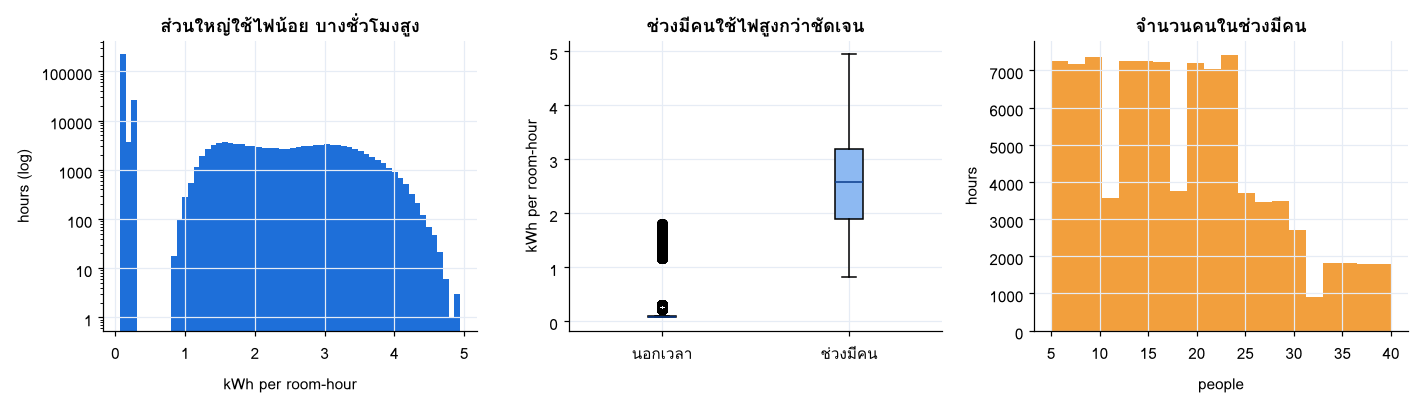

> **สรุปสั้น (n=350400):** ช่วงมีคนใช้ไฟค่ากลาง 2.58 kWh ต่อห้องต่อชั่วโมง นอกเวลา 0.082 kWh (ต่างกัน 31 เท่า)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ช่วงที่ไม่มีคน (73.2% ของชั่วโมง) ใช้ไฟค่ากลาง 0.082 kWh ช่วงมีคนค่ากลาง 2.58 kWh ค่าเฉลี่ยนอกเวลา 0.130 สูงกว่าค่ากลางเพราะบางห้องใช้ไฟนอกเวลาสูง

**💡 ความหมาย:** การใช้ไฟมี 2 ระดับชัดเจนตามช่วงเวลา การดูค่าเฉลี่ยรวมอย่างเดียวจะมองไม่เห็นความต่างนี้

**🎯 ข้อเสนอแนะ:** แยกวิเคราะห์ช่วงมีคนกับนอกเวลา และดูว่าห้องไหนนอกเวลาสูงกว่าปกติ (ดูหัวข้อ 2.4)

- ใช้ดูอะไร: ดูว่าการใช้ไฟกระจายอย่างไร
- อ่านอย่างไร: กราฟซ้ายแกนตั้งเป็นแบบล็อก แท่งสูงทางซ้ายคือชั่วโมงที่ใช้ไฟน้อยซึ่งมีมากที่สุด กล่องกลางเทียบนอกเวลากับช่วงมีคน
- วิเคราะห์ด้วยวิธี: ฮิสโทแกรมและบ็อกซ์พล็อต แยกตามช่วงเวลา

</details>

In [4]:
# distribution: histogram + boxplot for 2 key variables (energy, occupancy) and temperature
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(df[E], bins=60, color=BLUE)
ax[0].set_yscale("log"); ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%g" % v))
ax[0].set_title("ส่วนใหญ่ใช้ไฟน้อย บางชั่วโมงสูง"); ax[0].set_xlabel("kWh per room-hour"); ax[0].set_ylabel("hours (log)")
ax[1].boxplot([df.loc[~wk_mask, E], df.loc[wk_mask, E]], tick_labels=["นอกเวลา", "ช่วงมีคน"], patch_artist=True,
              boxprops=dict(facecolor=BLUE_L), medianprops=dict(color=BLUE_D))
ax[1].set_title("ช่วงมีคนใช้ไฟสูงกว่าชัดเจน"); ax[1].set_ylabel("kWh per room-hour")
ax[2].hist(df.loc[wk_mask, "occupancy_people"], bins=20, color=ORANGE)
ax[2].set_title("จำนวนคนในช่วงมีคน"); ax[2].set_xlabel("people"); ax[2].set_ylabel("hours")
plt.tight_layout(); plt.show()
m_on, m_off = df.loc[wk_mask, E].median(), df.loc[~wk_mask, E].median()
explain(
    short="ช่วงมีคนใช้ไฟค่ากลาง %.2f kWh ต่อห้องต่อชั่วโมง นอกเวลา %.3f kWh (ต่างกัน %.0f เท่า)" % (m_on, m_off, m_on / m_off),
    found="ช่วงที่ไม่มีคน (%.1f%% ของชั่วโมง) ใช้ไฟค่ากลาง %.3f kWh ช่วงมีคนค่ากลาง %.2f kWh ค่าเฉลี่ยนอกเวลา %.3f สูงกว่าค่ากลางเพราะบางห้องใช้ไฟนอกเวลาสูง" % (100 * (~wk_mask).mean(), m_off, m_on, df.loc[~wk_mask, E].mean()),
    meaning="การใช้ไฟมี 2 ระดับชัดเจนตามช่วงเวลา การดูค่าเฉลี่ยรวมอย่างเดียวจะมองไม่เห็นความต่างนี้",
    action="แยกวิเคราะห์ช่วงมีคนกับนอกเวลา และดูว่าห้องไหนนอกเวลาสูงกว่าปกติ (ดูหัวข้อ 2.4)",
    use="ดูว่าการใช้ไฟกระจายอย่างไร", read="กราฟซ้ายแกนตั้งเป็นแบบล็อก แท่งสูงทางซ้ายคือชั่วโมงที่ใช้ไฟน้อยซึ่งมีมากที่สุด กล่องกลางเทียบนอกเวลากับช่วงมีคน",
    method="ฮิสโทแกรมและบ็อกซ์พล็อต แยกตามช่วงเวลา", n=N_ROWS)

## 1.4 สมดุลของกลุ่ม (ประเภทห้อง และอาคาร)

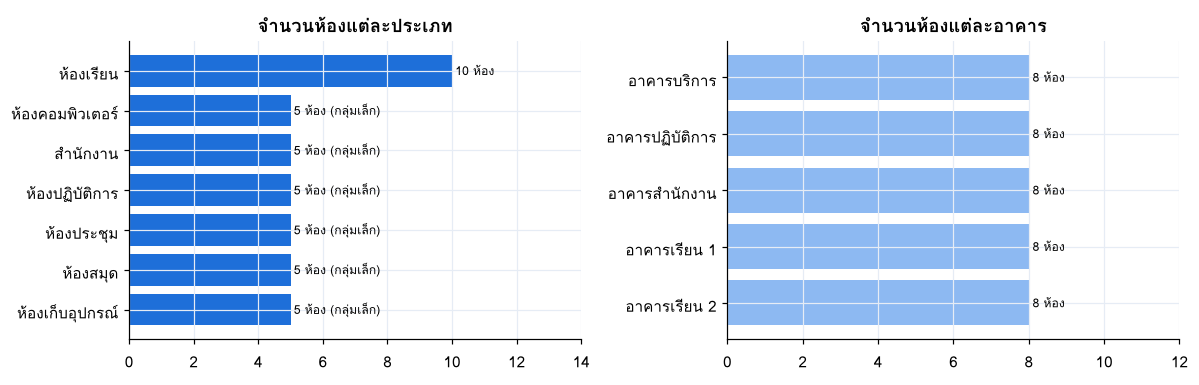

> **สรุปสั้น (n=40):** มี 7 ประเภทห้อง ห้องเรียนมากสุด 10 ห้อง อีก 6 ประเภทมีเพียง 5 ห้อง (ติดป้ายกลุ่มเล็ก)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** แต่ละอาคารมี 8 ห้องเท่ากัน ประเภทห้องที่มีน้อยกว่า 6 ห้อง: ห้องคอมพิวเตอร์, สำนักงาน, ห้องปฏิบัติการ, ห้องประชุม, ห้องสมุด, ห้องเก็บอุปกรณ์

**💡 ความหมาย:** ผลเฉลี่ยของกลุ่มเล็กอาจเปลี่ยนมากถ้าห้องเดียวผิดปกติ จึงควรอ่านตัวเลขกลุ่มเล็กอย่างระวัง แม้จำนวนชั่วโมงจะมาก แต่จำนวนห้องคือหน่วยอิสระจริง

**🎯 ข้อเสนอแนะ:** ในหน้าจัดอันดับ ให้ดูควบคู่กับรายห้องเสมอ และติดป้ายเตือนกลุ่มเล็ก (เกณฑ์ 6 ห้องเป็นค่าตั้งต้น)

- ใช้ดูอะไร: ดูว่ากลุ่มไหนมีข้อมูลน้อยจนเปรียบเทียบยาก
- อ่านอย่างไร: ตัวเลขข้างแท่งคือจำนวนห้อง ป้าย ⚠ คือกลุ่มเล็ก
- วิเคราะห์ด้วยวิธี: นับจำนวนห้องไม่ซ้ำในแต่ละกลุ่ม

</details>

In [5]:
# group balance: number of ROOMS per type / building (rooms are the real independent units, not hours)
rt = df.groupby("room_type")["room_id"].nunique().sort_values(ascending=False)
bd = df.groupby("building_name")["room_id"].nunique().sort_values(ascending=False)
def label(n):
    return "%d ห้อง" % n + (" (กลุ่มเล็ก)" if n < THR["small_group_rooms"] else "")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(rt.index[::-1], rt.values[::-1], color=BLUE)
for i, (k, v) in enumerate(zip(rt.index[::-1], rt.values[::-1])):
    ax[0].text(v + 0.1, i, label(v), va="center", fontsize=8)
ax[0].set_title("จำนวนห้องแต่ละประเภท"); ax[0].set_xlim(0, rt.max() + 4)
ax[1].barh(bd.index[::-1], bd.values[::-1], color=BLUE_L)
for i, (k, v) in enumerate(zip(bd.index[::-1], bd.values[::-1])):
    ax[1].text(v + 0.1, i, label(v), va="center", fontsize=8)
ax[1].set_title("จำนวนห้องแต่ละอาคาร"); ax[1].set_xlim(0, bd.max() + 4)
plt.tight_layout(); plt.show()
small_types = [k for k, v in rt.items() if v < THR["small_group_rooms"]]
explain(
    short="มี %d ประเภทห้อง ห้องเรียนมากสุด %d ห้อง อีก %d ประเภทมีเพียง %d ห้อง (ติดป้ายกลุ่มเล็ก)" % (len(rt), rt.max(), len(small_types), rt.min()),
    found="แต่ละอาคารมี %d ห้องเท่ากัน ประเภทห้องที่มีน้อยกว่า %d ห้อง: %s" % (bd.max(), THR["small_group_rooms"], ", ".join(small_types)),
    meaning="ผลเฉลี่ยของกลุ่มเล็กอาจเปลี่ยนมากถ้าห้องเดียวผิดปกติ จึงควรอ่านตัวเลขกลุ่มเล็กอย่างระวัง แม้จำนวนชั่วโมงจะมาก แต่จำนวนห้องคือหน่วยอิสระจริง",
    action="ในหน้าจัดอันดับ ให้ดูควบคู่กับรายห้องเสมอ และติดป้ายเตือนกลุ่มเล็ก (เกณฑ์ %d ห้องเป็นค่าตั้งต้น)" % THR["small_group_rooms"],
    use="ดูว่ากลุ่มไหนมีข้อมูลน้อยจนเปรียบเทียบยาก", read="ตัวเลขข้างแท่งคือจำนวนห้อง ป้าย ⚠ คือกลุ่มเล็ก",
    method="นับจำนวนห้องไม่ซ้ำในแต่ละกลุ่ม", n=N_ROOMS)

# ขั้นที่ 2 แนวโน้ม จัดอันดับ และความสัมพันธ์

## 2.0 ตารางสรุปรายห้อง (ตัวชี้วัดชุดเดียวใช้เทียบทุกกลุ่ม)

In [6]:
# one metric set for every group: kWh, kWh per room-hour, off-hours share (%)
EVE = df["is_off_hours"] & df["hour"].between(18, 22)
OTH = df["is_off_hours"] & ~df["hour"].between(18, 22)
OFF = df["is_off_hours"]
g = df.groupby("room_id")
room = g.agg(meter_id=("meter_id", "first"), building_id=("building_id", "first"), building_name=("building_name", "first"),
             room_type=("room_type", "first"), area_m2=("area_m2", "first"), capacity_people=("capacity_people", "first"),
             ac_count=("air_conditioner_count", "first"), total_kwh=(E, "sum"), mean_kwh_h=(E, "mean"), peak_kwh_h=(E, "max"))
room["p95_kwh_h"] = g[E].quantile(0.95)
room["off_kwh"] = df[OFF].groupby("room_id")[E].sum()
room["off_hours_n"] = df[OFF].groupby("room_id").size()
room["off_mean_kwh_h"] = df[OFF].groupby("room_id")[E].mean()
room["evening_mean_kwh_h"] = df[EVE].groupby("room_id")[E].mean()
room["evening_hours_n"] = df[EVE].groupby("room_id").size()
room["other_off_mean_kwh_h"] = df[OTH].groupby("room_id")[E].mean()
room["evening_ratio"] = room["evening_mean_kwh_h"] / room["other_off_mean_kwh_h"]
room["off_share_pct"] = 100 * room["off_kwh"] / room["total_kwh"]
room["weekend_mean_kwh_h"] = df[df["day_type"] == "weekend"].groupby("room_id")[E].mean()
room["weekday_mean_kwh_h"] = df[df["day_type"] == "weekday"].groupby("room_id")[E].mean()
room["occupied_mean_kwh_h"] = df[~OFF].groupby("room_id")[E].mean()
room["mean_people_occupied"] = df[~OFF].groupby("room_id")["occupancy_people"].mean()
room["outlier_count"] = df[df["flag_outlier"]].groupby("room_id").size()
room["outlier_count"] = room["outlier_count"].fillna(0).astype(int)

BASE = room["other_off_mean_kwh_h"].median()          # campus baseline: median off-hours kWh per hour
room["flag_evening_block"] = room["evening_ratio"] >= THR["evening_ratio"]
room["flag_continuous_baseline"] = room["other_off_mean_kwh_h"] >= THR["standby_x_baseline"] * BASE
room["flag_off_share"] = room["off_share_pct"] > THR["off_share_pct"]
room["evening_excess_kwh"] = ((room["evening_mean_kwh_h"] - room["other_off_mean_kwh_h"]).clip(lower=0) * room["evening_hours_n"]).where(room["flag_evening_block"], 0)
room["baseline_excess_kwh"] = ((room["other_off_mean_kwh_h"] - BASE).clip(lower=0) * room["off_hours_n"]).where(room["flag_continuous_baseline"], 0)
room = room.reset_index()
print("campus off-hours baseline (median of rooms): %.3f kWh per hour" % BASE)
display(room[["room_id", "building_id", "room_type", "ac_count", "total_kwh", "off_share_pct", "other_off_mean_kwh_h", "evening_ratio", "flag_evening_block", "flag_continuous_baseline"]].head(8).round(3))

campus off-hours baseline (median of rooms): 0.080 kWh per hour


,room_id,building_id,room_type,ac_count,total_kwh,off_share_pct,other_off_mean_kwh_h,evening_ratio,flag_evening_block,flag_continuous_baseline
0,B01-R01,B01,ห้องเรียน,3,8328.933,6.151,0.08,1.000,False,False
1,B01-R02,B01,ห้องคอมพิวเตอร์,2,8162.121,20.464,0.26,1.003,False,True
2,B01-R03,B01,ห้องปฏิบัติการ,1,4458.465,11.498,0.08,0.997,False,False
3,B01-R04,B01,สำนักงาน,3,8489.741,6.034,0.08,0.997,False,False
4,B01-R05,B01,ห้องประชุม,1,4715.533,10.891,0.08,1.001,False,False
5,B01-R06,B01,ห้องสมุด,1,4722.232,10.856,0.08,0.997,False,False
6,B01-R07,B01,ห้องเรียน,1,4454.450,11.516,0.08,1.002,False,False
7,B01-R08,B01,ห้องเก็บอุปกรณ์,1,4700.179,10.899,0.08,1.003,False,False


## 2.1 ภาพรวม: ใช้ไฟรวมเปลี่ยนตามเดือนอย่างไร

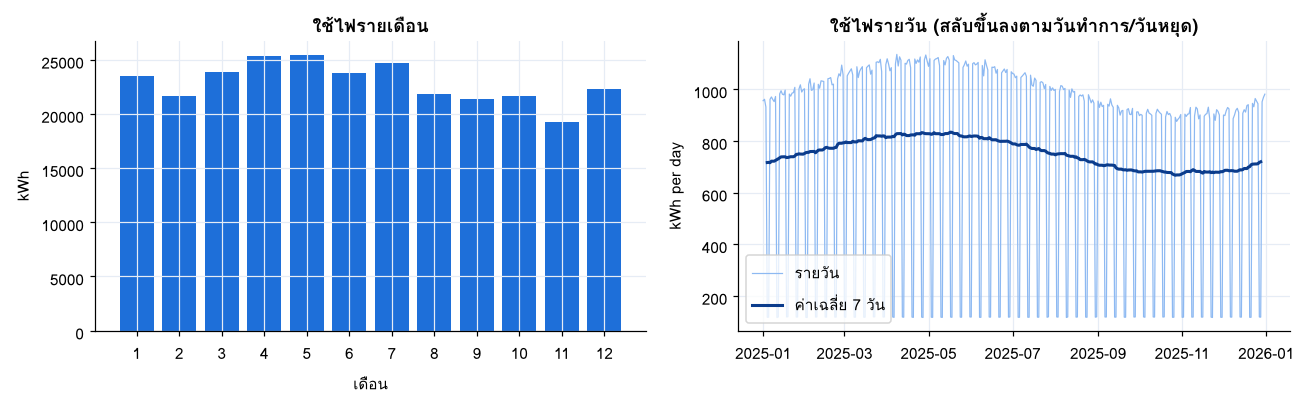

> **สรุปสั้น (n=350400):** ใช้ไฟสูงสุดเดือน 5 (25,442 kWh) ต่ำสุดเดือน 11 (19,298 kWh) ต่างกัน 31.8% ข้อมูลมีปีเดียว

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** รวมทั้งปี 274,748 kWh เฉลี่ย 22,896 kWh ต่อเดือน เดือนที่ใช้สูงสุดคือเดือน 5 อุณหภูมิเฉลี่ย 31.9 องศา เดือนต่ำสุดคือเดือน 11 อุณหภูมิเฉลี่ย 26.1 องศา สัดส่วนไฟนอกเวลารายเดือนอยู่ระหว่าง 10.8-14.5%

**💡 ความหมาย:** พบแนวโน้มที่เดือนอากาศร้อนใช้ไฟมากกว่า แต่ข้อมูลมีปีเดียว จึงยืนยันไม่ได้ว่า ค่าไฟสูงขึ้นเมื่อเทียบกับปีก่อน สัดส่วนไฟนอกเวลารายเดือนอยู่ในช่วงแคบ (เปลี่ยนตามจำนวนวันหยุดของเดือน) แปลว่าเป็นรูปแบบที่เกิดสม่ำเสมอ ไม่ใช่เหตุการณ์ครั้งเดียว

**🎯 ข้อเสนอแนะ:** ขอข้อมูลปีก่อนหน้าเพื่อเทียบแนวโน้มจริง และเริ่มตรวจนอกเวลาโดยไม่ต้องรอฤดูกาล (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่)

- ใช้ดูอะไร: ดูแนวโน้มใช้ไฟรวมตลอดปี
- อ่านอย่างไร: กราฟซ้ายคือยอดรวมแต่ละเดือน กราฟขวาเส้นหนาคือค่าเฉลี่ย 7 วันตัดผลวันหยุดออก
- วิเคราะห์ด้วยวิธี: รวม kWh รายเดือนและรายวัน ใช้ค่าเฉลี่ยเคลื่อนที่ 7 วัน

</details>

In [7]:
# monthly total and 7-day rolling mean of daily total
daily = df.groupby("date")[E].sum()
daily.index = pd.to_datetime(daily.index)
monthly = df.groupby("month").agg(total_kwh=(E, "sum"), mean_kwh_h=(E, "mean"), temp=("temperature_c", "mean"))
monthly["off_share_pct"] = 100 * df[OFF].groupby("month")[E].sum() / monthly["total_kwh"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(monthly.index, monthly["total_kwh"], color=BLUE)
ax[0].set_title("ใช้ไฟรายเดือน"); ax[0].set_xlabel("เดือน"); ax[0].set_ylabel("kWh"); ax[0].set_xticks(range(1, 13))
ax[1].plot(daily.index, daily.values, color=BLUE_L, lw=0.8, label="รายวัน")
ax[1].plot(daily.index, daily.rolling(7, center=True).mean(), color=BLUE_D, lw=2, label="ค่าเฉลี่ย 7 วัน")
ax[1].set_title("ใช้ไฟรายวัน (สลับขึ้นลงตามวันทำการ/วันหยุด)"); ax[1].set_ylabel("kWh per day"); ax[1].legend()
plt.tight_layout(); plt.show()
pk, lo = monthly["total_kwh"].idxmax(), monthly["total_kwh"].idxmin()
explain(
    short="ใช้ไฟสูงสุดเดือน %d (%s kWh) ต่ำสุดเดือน %d (%s kWh) ต่างกัน %.1f%% ข้อมูลมีปีเดียว" % (pk, format(round(monthly.loc[pk, "total_kwh"]), ","), lo, format(round(monthly.loc[lo, "total_kwh"]), ","), 100 * (monthly.loc[pk, "total_kwh"] / monthly.loc[lo, "total_kwh"] - 1)),
    found="รวมทั้งปี %s kWh เฉลี่ย %s kWh ต่อเดือน เดือนที่ใช้สูงสุดคือเดือน %d อุณหภูมิเฉลี่ย %.1f องศา เดือนต่ำสุดคือเดือน %d อุณหภูมิเฉลี่ย %.1f องศา สัดส่วนไฟนอกเวลารายเดือนอยู่ระหว่าง %.1f-%.1f%%" % (format(round(TOTAL), ","), format(round(TOTAL / 12), ","), pk, monthly.loc[pk, "temp"], lo, monthly.loc[lo, "temp"], monthly["off_share_pct"].min(), monthly["off_share_pct"].max()),
    meaning="พบแนวโน้มที่เดือนอากาศร้อนใช้ไฟมากกว่า แต่ข้อมูลมีปีเดียว จึงยืนยันไม่ได้ว่า ค่าไฟสูงขึ้นเมื่อเทียบกับปีก่อน สัดส่วนไฟนอกเวลารายเดือนอยู่ในช่วงแคบ (เปลี่ยนตามจำนวนวันหยุดของเดือน) แปลว่าเป็นรูปแบบที่เกิดสม่ำเสมอ ไม่ใช่เหตุการณ์ครั้งเดียว",
    action="ขอข้อมูลปีก่อนหน้าเพื่อเทียบแนวโน้มจริง และเริ่มตรวจนอกเวลาโดยไม่ต้องรอฤดูกาล (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่)",
    use="ดูแนวโน้มใช้ไฟรวมตลอดปี", read="กราฟซ้ายคือยอดรวมแต่ละเดือน กราฟขวาเส้นหนาคือค่าเฉลี่ย 7 วันตัดผลวันหยุดออก",
    method="รวม kWh รายเดือนและรายวัน ใช้ค่าเฉลี่ยเคลื่อนที่ 7 วัน", n=N_ROWS)

## 2.2 ใช้ไฟมากช่วงเวลาไหน (Peak)

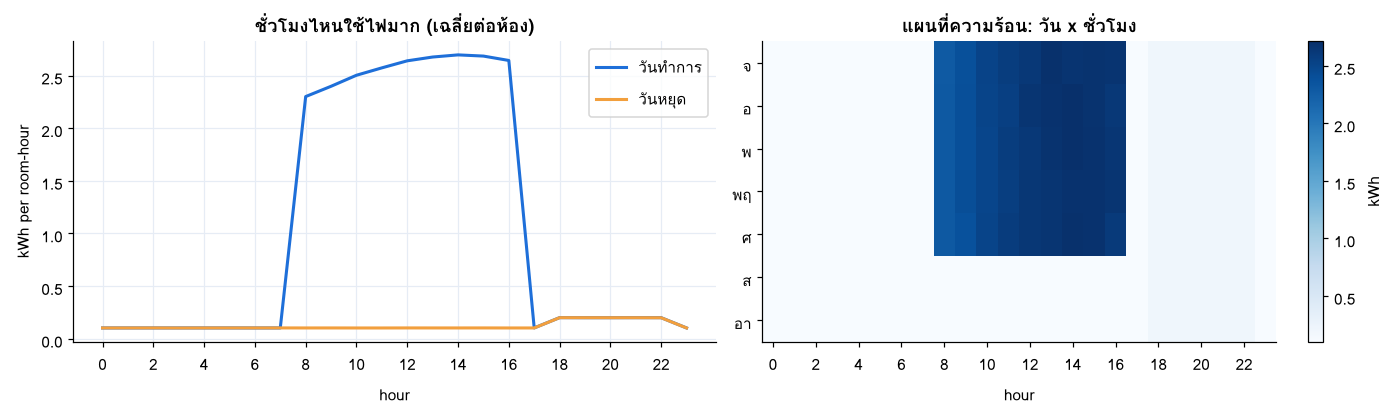

top 5 peak days:


,total_kwh,temp
date,,
2025-04-08,1135.6,31.9
2025-04-29,1133.2,32.2
2025-05-19,1131.0,31.9
2025-05-15,1127.2,32.1
2025-04-10,1126.1,32.0


top 5 rooms by highest hourly kWh (cleaned data; hourly energy, not kW demand):


,room_id,building_name,room_type,peak_kwh_h,p95_kwh_h
9,B02-R02,อาคารเรียน 2,ห้องคอมพิวเตอร์,4.94,3.88
25,B04-R02,อาคารสำนักงาน,ห้องคอมพิวเตอร์,4.94,3.99
29,B04-R06,อาคารสำนักงาน,ห้องสมุด,4.69,3.80
36,B05-R05,อาคารบริการ,ห้องประชุม,4.63,3.78
3,B01-R04,อาคารเรียน 1,สำนักงาน,4.63,3.79


> **สรุปสั้น (n=350400):** ใช้ไฟสูงสุดชั่วโมง 14:00 วันทำการ (เฉลี่ย 2.70 kWh ต่อห้อง) ช่วง 08:00-16:59 วันจันทร์-ศุกร์กินไฟ 87.8% ของทั้งปี

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** วันทำการเริ่มใช้ไฟสูงตอน 08:00 และลดลงหลัง 17:00 วันหยุดต่ำและเรียบ วันที่ใช้ไฟรวมสูงสุดคือ 2025-04-08 (1136 kWh อุณหภูมิเฉลี่ย 31.9 องศา) ห้องที่มีชั่วโมงสูงสุดคือ B02-R02 (4.94 kWh หลังจัดการค่าผิดปกติแล้ว)

**💡 ความหมาย:** ถ้าต้องการลดการใช้ไฟรวม ช่วงที่กินไฟมากที่สุดคือเวลาทำการ แต่ช่วงนอกเวลาเป็นส่วนที่ลดได้โดยไม่กระทบการเรียนการสอน ข้อมูลเป็น kWh รายชั่วโมง จึงบอกค่ากำลังไฟสูงสุด (kW) ไม่ได้

**🎯 ข้อเสนอแนะ:** เริ่มตรวจช่วงนอกเวลา (หัวข้อ 2.4) ก่อน แล้วค่อยดูการตั้งค่าแอร์ช่วง 12:00-15:00 ที่ใช้ไฟสูงสุดของวัน

- ใช้ดูอะไร: ดูว่าควรเริ่มตรวจช่วงไหน
- อ่านอย่างไร: กราฟซ้ายเส้นสีน้ำเงินคือวันทำการ สีส้มคือวันหยุด แผนที่ความร้อนยิ่งเข้มยิ่งใช้ไฟมาก
- วิเคราะห์ด้วยวิธี: ค่าเฉลี่ย kWh ต่อห้องต่อชั่วโมง แยกตามวันและชั่วโมง จัดอันดับวันและห้อง

</details>

In [8]:
# hourly profile by day type + heatmap hour x day of week; peak hour, peak days, peak rooms
prof = df.groupby(["day_type", "hour"])[E].mean().unstack(0)
heat = df.groupby(["dow", "hour"])[E].mean().unstack()
days = ["จ", "อ", "พ", "พฤ", "ศ", "ส", "อา"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ax[0].plot(prof.index, prof["weekday"], color=BLUE, lw=2, label="วันทำการ")
ax[0].plot(prof.index, prof["weekend"], color=ORANGE, lw=2, label="วันหยุด")
ax[0].set_title("ชั่วโมงไหนใช้ไฟมาก (เฉลี่ยต่อห้อง)"); ax[0].set_xlabel("hour"); ax[0].set_ylabel("kWh per room-hour"); ax[0].legend(); ax[0].set_xticks(range(0, 24, 2))
im = ax[1].imshow(heat.values, aspect="auto", cmap="Blues")
ax[1].set_yticks(range(7)); ax[1].set_yticklabels(days); ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xticklabels(range(0, 24, 2))
ax[1].set_title("แผนที่ความร้อน: วัน x ชั่วโมง"); ax[1].set_xlabel("hour"); ax[1].grid(False); plt.colorbar(im, ax=ax[1], label="kWh")
plt.tight_layout(); plt.show()

peak_hour = prof["weekday"].idxmax()
d_tot = df.groupby("date").agg(total_kwh=(E, "sum"), temp=("temperature_c", "mean"))
top_days = d_tot.sort_values("total_kwh", ascending=False).head(5)
sched = ((df["day_type"] == "weekday") & df["hour"].between(8, 16))
share_sched = 100 * df.loc[sched, E].sum() / TOTAL
top_peak_rooms = room.sort_values("peak_kwh_h", ascending=False).head(5)[["room_id", "building_name", "room_type", "peak_kwh_h", "p95_kwh_h"]]
print("top 5 peak days:"); display(top_days.round(1))
print("top 5 rooms by highest hourly kWh (cleaned data; hourly energy, not kW demand):"); display(top_peak_rooms.round(2))
explain(
    short="ใช้ไฟสูงสุดชั่วโมง %02d:00 วันทำการ (เฉลี่ย %.2f kWh ต่อห้อง) ช่วง 08:00-16:59 วันจันทร์-ศุกร์กินไฟ %.1f%% ของทั้งปี" % (peak_hour, prof.loc[peak_hour, "weekday"], share_sched),
    found="วันทำการเริ่มใช้ไฟสูงตอน 08:00 และลดลงหลัง 17:00 วันหยุดต่ำและเรียบ วันที่ใช้ไฟรวมสูงสุดคือ %s (%.0f kWh อุณหภูมิเฉลี่ย %.1f องศา) ห้องที่มีชั่วโมงสูงสุดคือ %s (%.2f kWh หลังจัดการค่าผิดปกติแล้ว)" % (top_days.index[0], top_days.iloc[0]["total_kwh"], top_days.iloc[0]["temp"], top_peak_rooms.iloc[0]["room_id"], top_peak_rooms.iloc[0]["peak_kwh_h"]),
    meaning="ถ้าต้องการลดการใช้ไฟรวม ช่วงที่กินไฟมากที่สุดคือเวลาทำการ แต่ช่วงนอกเวลาเป็นส่วนที่ลดได้โดยไม่กระทบการเรียนการสอน ข้อมูลเป็น kWh รายชั่วโมง จึงบอกค่ากำลังไฟสูงสุด (kW) ไม่ได้",
    action="เริ่มตรวจช่วงนอกเวลา (หัวข้อ 2.4) ก่อน แล้วค่อยดูการตั้งค่าแอร์ช่วง 12:00-15:00 ที่ใช้ไฟสูงสุดของวัน",
    use="ดูว่าควรเริ่มตรวจช่วงไหน", read="กราฟซ้ายเส้นสีน้ำเงินคือวันทำการ สีส้มคือวันหยุด แผนที่ความร้อนยิ่งเข้มยิ่งใช้ไฟมาก",
    method="ค่าเฉลี่ย kWh ต่อห้องต่อชั่วโมง แยกตามวันและชั่วโมง จัดอันดับวันและห้อง", n=N_ROWS)

## 2.3 ใช้ไฟมากที่สุดที่ไหน (อาคาร ห้อง และเจาะลึก)

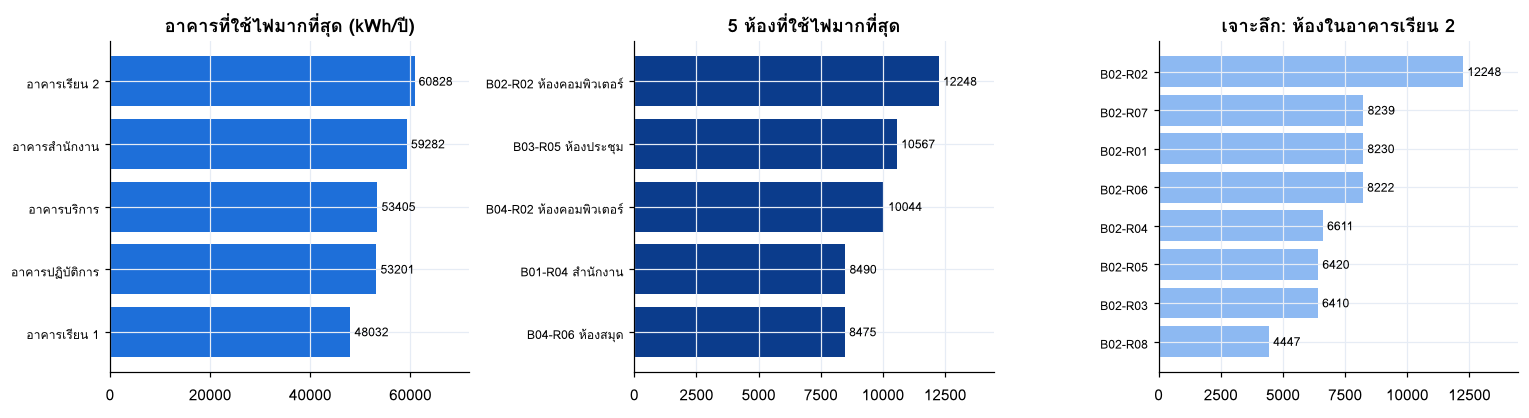

> **สรุปสั้น (n=40):** อาคารเรียน 2 ใช้ไฟมากสุด 60,828 kWh (22.1%) ห้องมากสุดคือ B02-R02 (12,248 kWh)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** อาคารสูงสุดกับต่ำสุดต่างกัน 26.6% (แต่ละอาคาร 8 ห้องเท่ากัน) 5 ห้องที่ใช้ไฟมากสุดมีเครื่องปรับอากาศ (เครื่อง:จำนวนห้อง) {3: 5} ในอาคารอาคารเรียน 2 ห้องที่ใช้ไฟมากสุดคือ B02-R02

**💡 ความหมาย:** ห้องที่ใช้ไฟมากมักเป็นห้องที่มีเครื่องปรับอากาศหลายเครื่อง ไม่ได้แปลว่าผิดปกติเสมอไป ต้องดูควบคู่กับการใช้ไฟนอกเวลา

**🎯 ข้อเสนอแนะ:** ใช้อันดับนี้เป็นจุดเริ่มดูภาพรวม แล้วไปดูอันดับนอกเวลา (2.4) เพื่อหาห้องที่ควรตรวจสอบ

- ใช้ดูอะไร: ตอบว่าใช้ไฟมากที่สุดที่ไหน
- อ่านอย่างไร: กราฟซ้ายอาคาร กราฟกลางห้อง กราฟขวาเจาะลึกห้องในอาคารที่ใช้ไฟมากที่สุด
- วิเคราะห์ด้วยวิธี: รวม kWh ทั้งปีตามอาคารและห้อง จัดอันดับ

</details>

In [9]:
# rankings: buildings (total + per room), top 5 rooms, drill-down into the top building
bld = room.groupby("building_name").agg(rooms=("room_id", "count"), total_kwh=("total_kwh", "sum"), kwh_per_room=("total_kwh", "mean")).sort_values("total_kwh", ascending=False)
bld["share_pct"] = 100 * bld["total_kwh"] / TOTAL
top_rooms = room.sort_values("total_kwh", ascending=False).head(5)
top_bld = bld.index[0]
drill = room[room["building_name"] == top_bld].sort_values("total_kwh", ascending=False)

def hbar(ax, labels, values, color, fmt="%.0f", note=None):
    ax.barh(list(labels)[::-1], list(values)[::-1], color=color)
    for i, v in enumerate(list(values)[::-1]):
        ax.text(v, i, " " + fmt % v, va="center", fontsize=8)
    ax.set_xlim(0, max(values) * 1.18)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
hbar(ax[0], bld.index, bld["total_kwh"], BLUE); ax[0].set_title("อาคารที่ใช้ไฟมากที่สุด (kWh/ปี)")
hbar(ax[1], top_rooms["room_id"] + " " + top_rooms["room_type"], top_rooms["total_kwh"], BLUE_D); ax[1].set_title("5 ห้องที่ใช้ไฟมากที่สุด")
hbar(ax[2], drill["room_id"], drill["total_kwh"], BLUE_L); ax[2].set_title("เจาะลึก: ห้องใน" + top_bld)
for a in ax:
    a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
ac_top = top_rooms["ac_count"].value_counts().to_dict()
explain(
    short="%s ใช้ไฟมากสุด %s kWh (%.1f%%) ห้องมากสุดคือ %s (%s kWh)" % (top_bld, format(round(bld.iloc[0]["total_kwh"]), ","), bld.iloc[0]["share_pct"], top_rooms.iloc[0]["room_id"], format(round(top_rooms.iloc[0]["total_kwh"]), ",")),
    found="อาคารสูงสุดกับต่ำสุดต่างกัน %.1f%% (แต่ละอาคาร %d ห้องเท่ากัน) 5 ห้องที่ใช้ไฟมากสุดมีเครื่องปรับอากาศ (เครื่อง:จำนวนห้อง) %s ในอาคาร%s ห้องที่ใช้ไฟมากสุดคือ %s" % (100 * (bld["total_kwh"].max() / bld["total_kwh"].min() - 1), bld["rooms"].iloc[0], ac_top, top_bld, drill.iloc[0]["room_id"]),
    meaning="ห้องที่ใช้ไฟมากมักเป็นห้องที่มีเครื่องปรับอากาศหลายเครื่อง ไม่ได้แปลว่าผิดปกติเสมอไป ต้องดูควบคู่กับการใช้ไฟนอกเวลา",
    action="ใช้อันดับนี้เป็นจุดเริ่มดูภาพรวม แล้วไปดูอันดับนอกเวลา (2.4) เพื่อหาห้องที่ควรตรวจสอบ",
    use="ตอบว่าใช้ไฟมากที่สุดที่ไหน", read="กราฟซ้ายอาคาร กราฟกลางห้อง กราฟขวาเจาะลึกห้องในอาคารที่ใช้ไฟมากที่สุด",
    method="รวม kWh ทั้งปีตามอาคารและห้อง จัดอันดับ", n=N_ROOMS)

## 2.4 นอกเวลาที่ไหนใช้ไฟสูง (ควรตรวจสอบเพิ่มเติม)

rooms above default threshold of 15% off-hours share: 7 of 40


,room_id,meter_id,building_name,room_type,ac_count,off_kwh,off_share_pct,off_mean_kwh_h,evening_ratio,pattern
28,B04-R05,M029,อาคารสำนักงาน,ห้องประชุม,1,2889.84,42.33,0.45,17.26,สูงช่วง 18-22 น.
9,B02-R02,M010,อาคารเรียน 2,ห้องคอมพิวเตอร์,3,4034.56,32.94,0.63,5.99,สูงช่วง 18-22 น. และมีฐานต่อเนื่อง
20,B03-R05,M021,อาคารปฏิบัติการ,ห้องประชุม,3,2885.00,27.30,0.45,17.26,สูงช่วง 18-22 น.
33,B05-R02,M034,อาคารบริการ,ห้องคอมพิวเตอร์,1,1664.42,27.23,0.26,1.00,ใช้ต่อเนื่องทั้งวัน
17,B03-R02,M018,อาคารปฏิบัติการ,ห้องคอมพิวเตอร์,2,1668.10,21.16,0.26,1.00,ใช้ต่อเนื่องทั้งวัน
1,B01-R02,M002,อาคารเรียน 1,ห้องคอมพิวเตอร์,2,1670.33,20.46,0.26,1.00,ใช้ต่อเนื่องทั้งวัน
25,B04-R02,M026,อาคารสำนักงาน,ห้องคอมพิวเตอร์,3,1664.48,16.57,0.26,1.00,ใช้ต่อเนื่องทั้งวัน


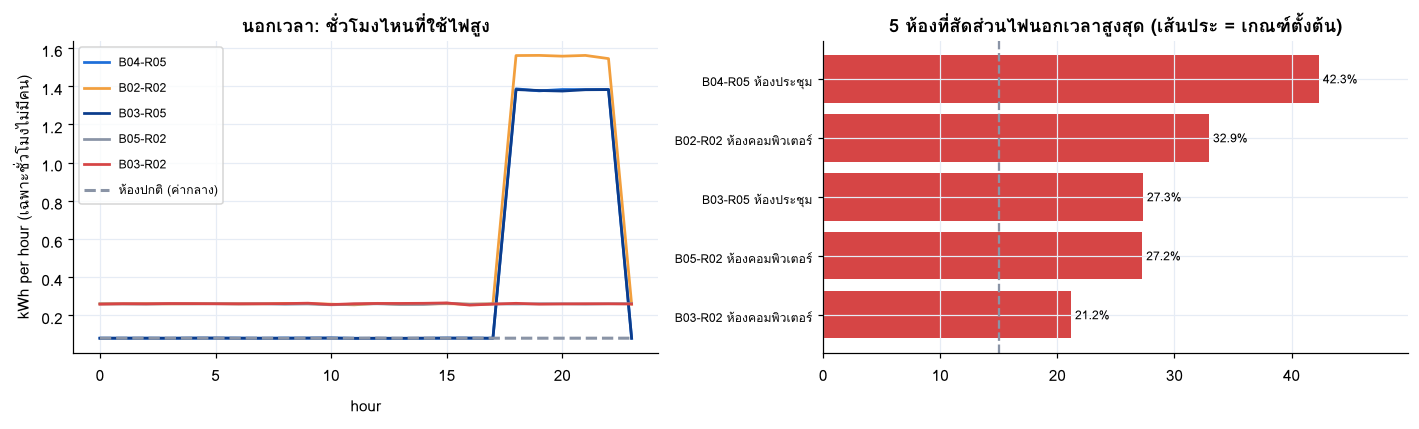

ranking by room type (most rooms to check first):


,rooms,rooms_to_check,off_share_pct,rooms_to_check_pct,warning
room_type,,,,,
ห้องคอมพิวเตอร์,5,5,23.7,100.0,⚠ กลุ่มเล็ก
ห้องประชุม,5,2,18.9,40.0,⚠ กลุ่มเล็ก
ห้องเก็บอุปกรณ์,5,0,10.3,0.0,⚠ กลุ่มเล็ก
ห้องปฏิบัติการ,5,0,9.0,0.0,⚠ กลุ่มเล็ก
สำนักงาน,5,0,8.3,0.0,⚠ กลุ่มเล็ก
ห้องสมุด,5,0,7.8,0.0,⚠ กลุ่มเล็ก
ห้องเรียน,10,0,7.8,0.0,


ranking by building:


,rooms,rooms_to_check,off_share_pct,rooms_to_check_pct,warning
building_name,,,,,
อาคารสำนักงาน,8,2,13.2,25.0,
อาคารปฏิบัติการ,8,2,13.1,25.0,
อาคารเรียน 1,8,1,11.0,12.5,
อาคารเรียน 2,8,1,10.9,12.5,
อาคารบริการ,8,1,10.3,12.5,


> **สรุปสั้น (n=40):** 7 จาก 40 ห้อง สัดส่วนไฟนอกเวลาเกิน 15% (เกณฑ์ตั้งต้น) สูงสุดคือ B04-R05 42.3%

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ห้อง B04-R05 ใช้ไฟนอกเวลา 42.3% ของที่ใช้ทั้งปี (ห้องทั่วไปประมาณ 8.0%) ประเภทห้องที่มีห้องควรตรวจมากสุดคือ ห้องคอมพิวเตอร์ (5 จาก 5 ห้อง) 3 ห้องมีรูปแบบสูงช่วง 18:00-22:59 ในชั่วโมงที่จำนวนคนเป็น 0 ทุกวันตลอดปี ไม่ใช่เฉพาะบางเดือน

**💡 ความหมาย:** เป็นการใช้ไฟสูงผิดปกตินอกเวลาการใช้งาน ข้อมูลบอกไม่ได้ว่ามาจากอุปกรณ์ใด จึงเป็นห้องที่ควรตรวจสอบเพิ่มเติม ตัวเลขนี้เป็นเกณฑ์ตั้งต้น ไม่ใช่มาตรฐานทางการ

**🎯 ข้อเสนอแนะ:** ให้ฝ่ายอาคารสถานที่ตรวจห้องตามตารางภายใน 1 สัปดาห์ ดูการตั้งเวลาเปิด-ปิดและสถานะอุปกรณ์หลัง 18:00 น. แล้วเทียบผลหลังตรวจ

- ใช้ดูอะไร: หาห้องที่ใช้ไฟนอกเวลาสูง
- อ่านอย่างไร: กราฟซ้ายเส้นสีที่พุ่งขึ้นช่วงเย็นคือห้องที่ควรตรวจ เส้นประเทาคือห้องปกติ กราฟขวาแท่งยาวคือสัดส่วนสูง
- วิเคราะห์ด้วยวิธี: นอกเวลา = ชั่วโมงที่จำนวนคนเป็น 0 สัดส่วน = kWh นอกเวลา / kWh ทั้งปีของห้องนั้น เทียบเกณฑ์ตั้งต้น

</details>

In [10]:
# off-hours = occupancy 0. rank by absolute kWh and by share of own kWh. pass/fail uses a DEFAULT threshold.
off_rank = room.sort_values("off_kwh", ascending=False).head(5)
share_rank = room.sort_values("off_share_pct", ascending=False).head(5)
check = room[room["flag_off_share"]].sort_values("off_share_pct", ascending=False)
def pattern(r):
    if r["flag_evening_block"] and r["flag_continuous_baseline"]:
        return "สูงช่วง 18-22 น. และมีฐานต่อเนื่อง"
    if r["flag_evening_block"]:
        return "สูงช่วง 18-22 น."
    if r["flag_continuous_baseline"]:
        return "ใช้ต่อเนื่องทั้งวัน"
    return "-"
room["pattern"] = room.apply(pattern, axis=1)
check = room[room["flag_off_share"]].sort_values("off_share_pct", ascending=False)
print("rooms above default threshold of %.0f%% off-hours share: %d of %d" % (THR["off_share_pct"], len(check), N_ROOMS))
display(check[["room_id", "meter_id", "building_name", "room_type", "ac_count", "off_kwh", "off_share_pct", "off_mean_kwh_h", "evening_ratio", "pattern"]].round(2))

# hourly pattern of the rooms to check vs a typical room
typ = room[~room["flag_off_share"]]["room_id"]
hp = df[OFF].groupby(["room_id", "hour"])[E].mean().unstack()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for rid in check["room_id"].head(5):
    ax[0].plot(hp.columns, hp.loc[rid], lw=1.8, label=rid)
ax[0].plot(hp.columns, hp.loc[typ].median(), color=GREY, ls="--", lw=2, label="ห้องปกติ (ค่ากลาง)")
ax[0].set_title("นอกเวลา: ชั่วโมงไหนที่ใช้ไฟสูง"); ax[0].set_xlabel("hour"); ax[0].set_ylabel("kWh per hour (เฉพาะชั่วโมงไม่มีคน)"); ax[0].legend(fontsize=8)
hbar(ax[1], share_rank["room_id"] + " " + share_rank["room_type"], share_rank["off_share_pct"], RED, fmt="%.1f%%")
ax[1].axvline(THR["off_share_pct"], color=GREY, ls="--"); ax[1].set_title("5 ห้องที่สัดส่วนไฟนอกเวลาสูงสุด (เส้นประ = เกณฑ์ตั้งต้น)")
ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

# group ranking: which groups have the most rooms above the threshold
def group_fail(col):
    t = room.groupby(col).agg(rooms=("room_id", "count"), rooms_to_check=("flag_off_share", "sum"), off_share_pct=("off_share_pct", "mean"))
    t["rooms_to_check_pct"] = 100 * t["rooms_to_check"] / t["rooms"]
    t["warning"] = np.where(t["rooms"] < THR["small_group_rooms"], "⚠ กลุ่มเล็ก", "")
    return t.sort_values(["rooms_to_check_pct", "off_share_pct"], ascending=False)
gf_type, gf_bld = group_fail("room_type"), group_fail("building_name")
print("ranking by room type (most rooms to check first):"); display(gf_type.round(1))
print("ranking by building:"); display(gf_bld.round(1))
best = check.iloc[0]
explain(
    short="%d จาก %d ห้อง สัดส่วนไฟนอกเวลาเกิน %.0f%% (เกณฑ์ตั้งต้น) สูงสุดคือ %s %.1f%%" % (len(check), N_ROOMS, THR["off_share_pct"], best["room_id"], best["off_share_pct"]),
    found="ห้อง %s ใช้ไฟนอกเวลา %.1f%% ของที่ใช้ทั้งปี (ห้องทั่วไปประมาณ %.1f%%) ประเภทห้องที่มีห้องควรตรวจมากสุดคือ %s (%d จาก %d ห้อง) %d ห้องมีรูปแบบสูงช่วง 18:00-22:59 ในชั่วโมงที่จำนวนคนเป็น 0 ทุกวันตลอดปี ไม่ใช่เฉพาะบางเดือน" % (best["room_id"], best["off_share_pct"], room.loc[~room["flag_off_share"], "off_share_pct"].median(), gf_type.index[0], gf_type.iloc[0]["rooms_to_check"], gf_type.iloc[0]["rooms"], int(room["flag_evening_block"].sum())),
    meaning="เป็นการใช้ไฟสูงผิดปกตินอกเวลาการใช้งาน ข้อมูลบอกไม่ได้ว่ามาจากอุปกรณ์ใด จึงเป็นห้องที่ควรตรวจสอบเพิ่มเติม ตัวเลขนี้เป็นเกณฑ์ตั้งต้น ไม่ใช่มาตรฐานทางการ",
    action="ให้ฝ่ายอาคารสถานที่ตรวจห้องตามตารางภายใน 1 สัปดาห์ ดูการตั้งเวลาเปิด-ปิดและสถานะอุปกรณ์หลัง 18:00 น. แล้วเทียบผลหลังตรวจ",
    use="หาห้องที่ใช้ไฟนอกเวลาสูง", read="กราฟซ้ายเส้นสีที่พุ่งขึ้นช่วงเย็นคือห้องที่ควรตรวจ เส้นประเทาคือห้องปกติ กราฟขวาแท่งยาวคือสัดส่วนสูง",
    method="นอกเวลา = ชั่วโมงที่จำนวนคนเป็น 0 สัดส่วน = kWh นอกเวลา / kWh ทั้งปีของห้องนั้น เทียบเกณฑ์ตั้งต้น", n=N_ROOMS)

## 2.5 ห้องคอมพิวเตอร์ยังใช้ไฟต่อเนื่องแค่ไหน ในช่วงที่ไม่มีคน

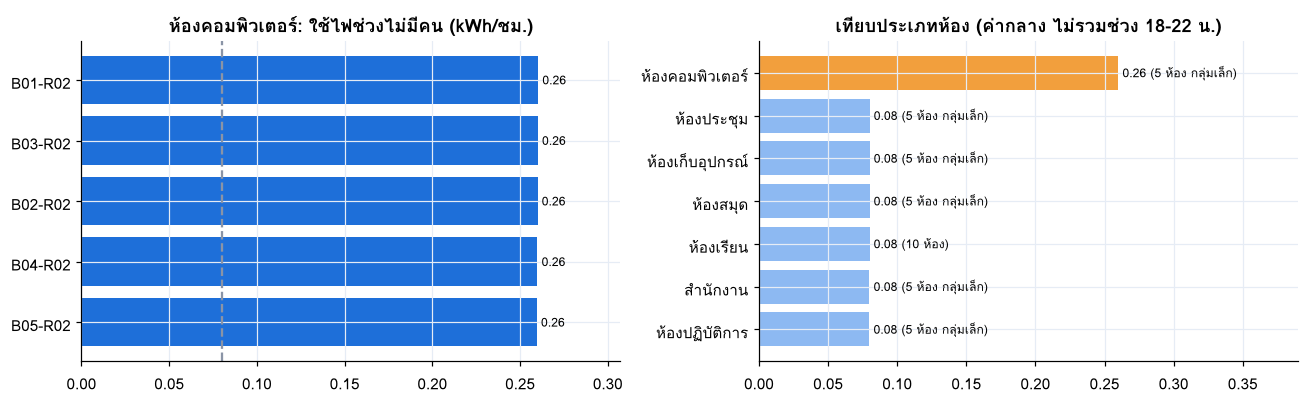

> **สรุปสั้น (n=5):** ห้องคอมพิวเตอร์ 5 ห้องใช้ไฟช่วงไม่มีคนค่ากลาง 0.26 kWh/ชม. สูงกว่าห้องอื่น 3.2 เท่า

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ห้องคอมพิวเตอร์ทั้ง 5 ห้องใช้ไฟต่อเนื่องแม้ไม่มีคนใช้ ค่าอยู่ระหว่าง 0.26-0.26 kWh/ชม. (ห้องอื่นค่ากลาง 0.080) ทุกห้องใกล้เคียงกัน จึงไม่มีห้องใดเด่นกว่ากัน รวมไฟนอกเวลา 10,702 kWh ต่อปี (รวมช่วงเย็นของห้องที่มีรูปแบบช่วงเย็นด้วย)

**💡 ความหมาย:** อาจมีการใช้พลังงานจากอุปกรณ์หรือระบบที่ทำงานต่อเนื่อง จึงควรตรวจสอบเพิ่มเติม ข้อมูลไม่ได้ระบุอุปกรณ์ จึงสรุปสาเหตุไม่ได้ และอาจเป็นการใช้งานที่จำเป็น เช่น เครื่องแม่ข่ายหรือเครือข่าย

**🎯 ข้อเสนอแนะ:** สอบถามผู้ดูแลห้องว่ามีอุปกรณ์ที่ต้องเปิดตลอดเวลาหรือไม่ ถ้าไม่จำเป็นให้ตั้งเวลาปิด (ผู้รับผิดชอบ: ผู้ดูแลห้องคอมพิวเตอร์ ภายใน 1 เดือน)

- ใช้ดูอะไร: ดูว่าห้องคอมพิวเตอร์ใช้ไฟต่อเนื่องในช่วงไม่มีคนมากน้อยเพียงใด
- อ่านอย่างไร: กราฟซ้ายแท่งยาวคือห้องที่ใช้ไฟช่วงไม่มีคนสูง เส้นประคือค่ากลางของห้องประเภทอื่น กราฟขวาเทียบประเภทห้อง
- วิเคราะห์ด้วยวิธี: ใช้ค่าเฉลี่ย kWh ต่อชั่วโมงในช่วงไม่มีคน ตัดช่วง 18-22 น. ออกเพื่อไม่ปนกับรูปแบบช่วงเย็น

</details>

In [11]:
# computer rooms vs other room types: off-hours kWh per hour, ranked
comp = room[room["room_type"] == "ห้องคอมพิวเตอร์"].sort_values("other_off_mean_kwh_h", ascending=False)
others = room[room["room_type"] != "ห้องคอมพิวเตอร์"]
by_type = room.groupby("room_type").agg(rooms=("room_id", "count"), off_kwh_per_hour=("other_off_mean_kwh_h", "median")).sort_values("off_kwh_per_hour", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
hbar(ax[0], comp["room_id"], comp["other_off_mean_kwh_h"], BLUE, fmt="%.2f"); ax[0].set_title("ห้องคอมพิวเตอร์: ใช้ไฟช่วงไม่มีคน (kWh/ชม.)")
ax[0].axvline(others["other_off_mean_kwh_h"].median(), color=GREY, ls="--"); 
ax[1].barh(by_type.index[::-1], by_type["off_kwh_per_hour"].values[::-1], color=[ORANGE if k == "ห้องคอมพิวเตอร์" else BLUE_L for k in by_type.index[::-1]])
for i, (k, v, n) in enumerate(zip(by_type.index[::-1], by_type["off_kwh_per_hour"].values[::-1], by_type["rooms"].values[::-1])):
    ax[1].text(v, i, " %.2f (%d ห้อง%s)" % (v, n, " กลุ่มเล็ก" if n < THR["small_group_rooms"] else ""), va="center", fontsize=8)
ax[1].set_xlim(0, by_type["off_kwh_per_hour"].max() * 1.5); ax[1].set_title("เทียบประเภทห้อง (ค่ากลาง ไม่รวมช่วง 18-22 น.)")
plt.tight_layout(); plt.show()
ratio_c = comp["other_off_mean_kwh_h"].median() / others["other_off_mean_kwh_h"].median()
tot_c = comp["off_kwh"].sum()
explain(
    short="ห้องคอมพิวเตอร์ %d ห้องใช้ไฟช่วงไม่มีคนค่ากลาง %.2f kWh/ชม. สูงกว่าห้องอื่น %.1f เท่า" % (len(comp), comp["other_off_mean_kwh_h"].median(), ratio_c),
    found="ห้องคอมพิวเตอร์ทั้ง %d ห้องใช้ไฟต่อเนื่องแม้ไม่มีคนใช้ ค่าอยู่ระหว่าง %.2f-%.2f kWh/ชม. (ห้องอื่นค่ากลาง %.3f) %s รวมไฟนอกเวลา %s kWh ต่อปี (รวมช่วงเย็นของห้องที่มีรูปแบบช่วงเย็นด้วย)" % (len(comp), comp["other_off_mean_kwh_h"].min(), comp["other_off_mean_kwh_h"].max(), others["other_off_mean_kwh_h"].median(), "ทุกห้องใกล้เคียงกัน จึงไม่มีห้องใดเด่นกว่ากัน" if comp["other_off_mean_kwh_h"].max() - comp["other_off_mean_kwh_h"].min() < 0.02 else "ห้องสูงสุดคือ " + comp.iloc[0]["room_id"], format(round(tot_c), ",")),
    meaning="อาจมีการใช้พลังงานจากอุปกรณ์หรือระบบที่ทำงานต่อเนื่อง จึงควรตรวจสอบเพิ่มเติม ข้อมูลไม่ได้ระบุอุปกรณ์ จึงสรุปสาเหตุไม่ได้ และอาจเป็นการใช้งานที่จำเป็น เช่น เครื่องแม่ข่ายหรือเครือข่าย",
    action="สอบถามผู้ดูแลห้องว่ามีอุปกรณ์ที่ต้องเปิดตลอดเวลาหรือไม่ ถ้าไม่จำเป็นให้ตั้งเวลาปิด (ผู้รับผิดชอบ: ผู้ดูแลห้องคอมพิวเตอร์ ภายใน 1 เดือน)",
    use="ดูว่าห้องคอมพิวเตอร์ใช้ไฟต่อเนื่องในช่วงไม่มีคนมากน้อยเพียงใด", read="กราฟซ้ายแท่งยาวคือห้องที่ใช้ไฟช่วงไม่มีคนสูง เส้นประคือค่ากลางของห้องประเภทอื่น กราฟขวาเทียบประเภทห้อง",
    method="ใช้ค่าเฉลี่ย kWh ต่อชั่วโมงในช่วงไม่มีคน ตัดช่วง 18-22 น. ออกเพื่อไม่ปนกับรูปแบบช่วงเย็น", n=len(comp))

## 2.6 วันหยุดที่ไหนยังใช้ไฟสูง

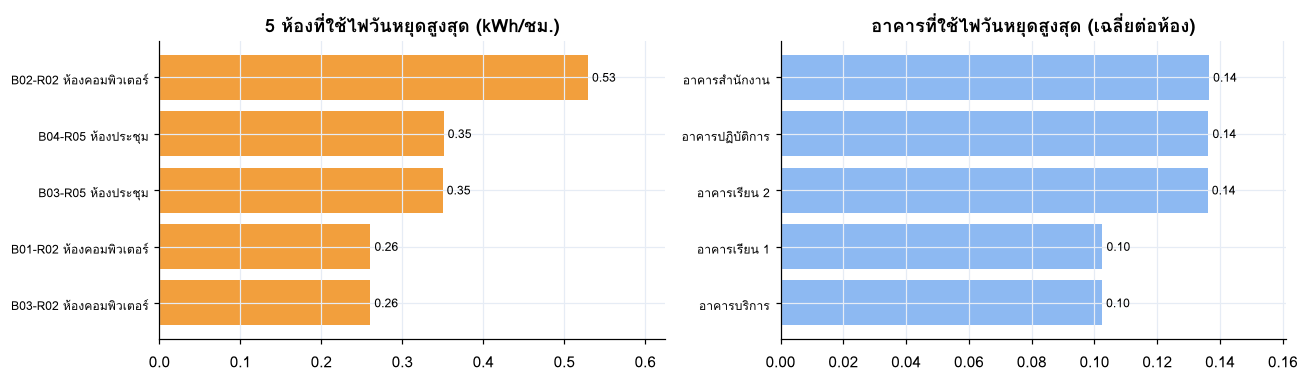

> **สรุปสั้น (n=99840):** วันหยุดใช้ไฟเฉลี่ย 0.12 kWh/ห้อง/ชม. ต่ำกว่าวันทำการ 88% ห้องที่ยังสูงสุดคือ B02-R02 (0.53)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** วันทำการเฉลี่ย 1.05 วันหยุดเฉลี่ย 0.12 kWh/ห้อง/ชม. ห้องทั่วไปใช้ไฟวันหยุดค่ากลาง 0.080 ห้องใน 5 อันดับสูงกว่าห้องทั่วไป 3.3-6.6 เท่า อาคารที่สูงสุดคือ อาคารสำนักงาน

**💡 ความหมาย:** วันหยุดในข้อมูลหมายถึงเสาร์-อาทิตย์เท่านั้น (ไม่มีปฏิทินนักขัตฤกษ์) ห้องที่ยังใช้ไฟสูงในวันหยุดทั้งที่ไม่มีคน ควรตรวจสอบเพิ่มเติม

**🎯 ข้อเสนอแนะ:** นำรายชื่อห้องเข้าตรวจพร้อมรายการนอกเวลา และขอปฏิทินวันหยุดของสถานศึกษาเพื่อแยกวันหยุดพิเศษ

- ใช้ดูอะไร: หาห้องที่ยังใช้ไฟสูงในวันหยุด
- อ่านอย่างไร: แท่งยาวคือห้องหรืออาคารที่ใช้ไฟวันหยุดสูง
- วิเคราะห์ด้วยวิธี: เฉลี่ย kWh ต่อห้องต่อชั่วโมงเฉพาะเสาร์-อาทิตย์ แล้วจัดอันดับ

</details>

In [12]:
# weekend (Saturday-Sunday only; no public holiday calendar in the data)
wkend = df[df["day_type"] == "weekend"]
wd_all = df[df["day_type"] == "weekday"][E].mean(); we_all = wkend[E].mean()
top_we = room.sort_values("weekend_mean_kwh_h", ascending=False).head(5)
bw = room.groupby("building_name")["weekend_mean_kwh_h"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
hbar(ax[0], top_we["room_id"] + " " + top_we["room_type"], top_we["weekend_mean_kwh_h"], ORANGE, fmt="%.2f"); ax[0].set_title("5 ห้องที่ใช้ไฟวันหยุดสูงสุด (kWh/ชม.)")
hbar(ax[1], bw.index, bw.values, BLUE_L, fmt="%.2f"); ax[1].set_title("อาคารที่ใช้ไฟวันหยุดสูงสุด (เฉลี่ยต่อห้อง)")
for a in ax: a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
typ_we = room["weekend_mean_kwh_h"].median()
explain(
    short="วันหยุดใช้ไฟเฉลี่ย %.2f kWh/ห้อง/ชม. ต่ำกว่าวันทำการ %.0f%% ห้องที่ยังสูงสุดคือ %s (%.2f)" % (we_all, 100 * (1 - we_all / wd_all), top_we.iloc[0]["room_id"], top_we.iloc[0]["weekend_mean_kwh_h"]),
    found="วันทำการเฉลี่ย %.2f วันหยุดเฉลี่ย %.2f kWh/ห้อง/ชม. ห้องทั่วไปใช้ไฟวันหยุดค่ากลาง %.3f ห้องใน 5 อันดับสูงกว่าห้องทั่วไป %.1f-%.1f เท่า อาคารที่สูงสุดคือ %s" % (wd_all, we_all, typ_we, top_we["weekend_mean_kwh_h"].min() / typ_we, top_we["weekend_mean_kwh_h"].max() / typ_we, bw.index[0]),
    meaning="วันหยุดในข้อมูลหมายถึงเสาร์-อาทิตย์เท่านั้น (ไม่มีปฏิทินนักขัตฤกษ์) ห้องที่ยังใช้ไฟสูงในวันหยุดทั้งที่ไม่มีคน ควรตรวจสอบเพิ่มเติม",
    action="นำรายชื่อห้องเข้าตรวจพร้อมรายการนอกเวลา และขอปฏิทินวันหยุดของสถานศึกษาเพื่อแยกวันหยุดพิเศษ",
    use="หาห้องที่ยังใช้ไฟสูงในวันหยุด", read="แท่งยาวคือห้องหรืออาคารที่ใช้ไฟวันหยุดสูง",
    method="เฉลี่ย kWh ต่อห้องต่อชั่วโมงเฉพาะเสาร์-อาทิตย์ แล้วจัดอันดับ", n=len(wkend))

## 2.7 จำนวนคนและจำนวนแอร์ กับการใช้ไฟ (ตรวจตัวแปรร่วมก่อนสรุป)

,all hours,occupied hours only,"occupied hours, within each room"
occupancy_people,0.834,0.163,0.327
air_conditioner_count,0.167,0.873,NaN


,std_effect_kwh_per_1sd,p_value
occupancy_people_z,0.1348,0.0000
air_conditioner_count_z,0.6877,0.0000
temperature_c_z,0.2684,0.0000
relative_humidity_percent_z,-0.0001,0.9292
area_m2_z,-0.0208,0.0000


R-squared: 0.908 | n=93960


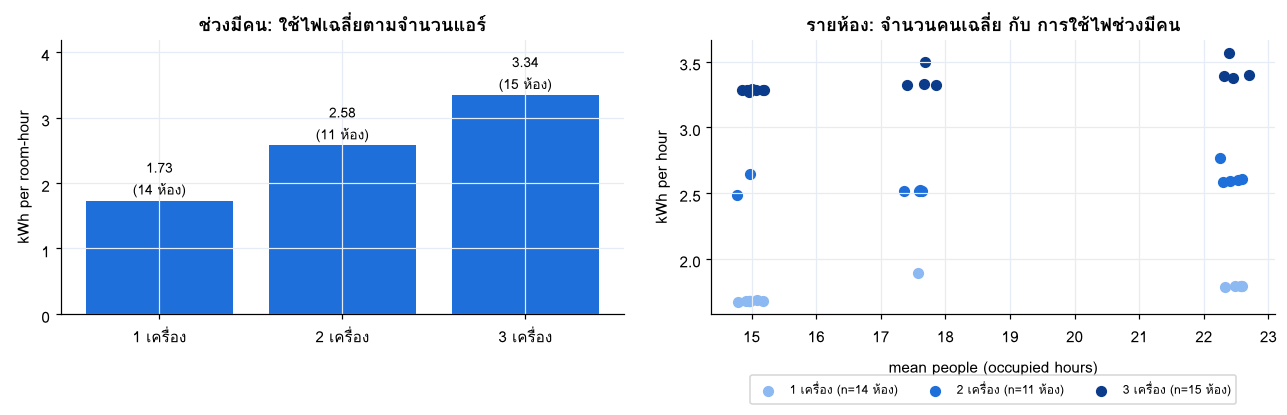

top 5 rooms by kWh per person-hour relative to rooms with the same number of air conditioners:


,kwh,people_hours,kwh_per_person_hour,building_name,room_type,ac_count,vs_same_ac_median
room_id,,,,,,,
B03-R02,6216.634,35197,0.177,อาคารปฏิบัติการ,ห้องคอมพิวเตอร์,2,1.238
B03-R07,5827.600,34709,0.168,อาคารปฏิบัติการ,ห้องเรียน,2,1.177
B04-R07,7714.489,34875,0.221,อาคารสำนักงาน,ห้องเรียน,3,1.119
B02-R06,7708.863,35075,0.220,อาคารเรียน 2,ห้องสมุด,3,1.112
B02-R07,7726.640,35245,0.219,อาคารเรียน 2,ห้องเรียน,3,1.109


> **สรุปสั้น (n=93960):** แอร์อธิบายการใช้ไฟได้ชัดกว่าจำนวนคน (ผลต่อ 1 SD: แอร์ 0.69 vs คน 0.13 kWh) ความสัมพันธ์กับจำนวนคนที่เห็นตอนรวมทุกชั่วโมง 0.83 ลดเหลือ 0.16 เมื่อดูเฉพาะช่วงมีคน

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ห้องที่มีแอร์ 1/2/3 เครื่องใช้ไฟช่วงมีคนเฉลี่ย 1.73 / 2.58 / 3.34 kWh ตามลำดับ ความสัมพันธ์ของจำนวนคนกับไฟสูงมากเมื่อรวมทุกชั่วโมง (r=0.83) เพราะกลางคืนทั้งคนและไฟต่ำพร้อมกัน เมื่อดูเฉพาะช่วงมีคนเหลือ r=0.16 และเมื่อควบคุมแอร์ อุณหภูมิ ความชื้น พื้นที่ ผลของจำนวนคนยังพบอยู่ (0.13 kWh ต่อ 1 SD, p<0.001) ห้องที่ใช้ไฟต่อคนสูงกว่าห้องแอร์เท่ากันมากสุดคือ B03-R02 (1.24 เท่า)

**💡 ความหมาย:** พบความสัมพันธ์ ไม่ได้พิสูจน์สาเหตุ การดูจำนวนคนอย่างเดียวจะประเมินเกินจริง เพราะต้องแยกผลของช่วงเวลาและจำนวนแอร์ออกก่อน

**🎯 ข้อเสนอแนะ:** เวลาเปรียบเทียบห้อง ให้เทียบกับห้องที่มีแอร์เท่ากัน ห้องใน 5 อันดับตารางข้างบนควรตรวจการตั้งค่าแอร์ (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่)

- ใช้ดูอะไร: ดูว่าจำนวนคนและจำนวนแอร์สัมพันธ์กับการใช้ไฟอย่างไร
- อ่านอย่างไร: กราฟซ้ายแท่งสูงคือห้องที่มีแอร์มาก กราฟขวาแต่ละจุดคือห้อง สีแยกตามจำนวนแอร์
- วิเคราะห์ด้วยวิธี: เทียบสหสัมพันธ์ก่อน-หลังแยกช่วงเวลา และถดถอยเชิงเส้นด้วยตัวแปรมาตรฐาน (ควบคุมหลายตัวพร้อมกัน)

</details>

In [13]:
# confounding check: raw correlation looks strong because BOTH people and kWh are low at night. control it.
occ = df[~OFF].copy()
def r(a, b, d):
    return d[a].corr(d[b])
def within(d, a, b, by):
    x = d[a] - d.groupby(by)[a].transform("mean"); y = d[b] - d.groupby(by)[b].transform("mean")
    return x.corr(y)
cor = pd.DataFrame({
    "all hours": [r(E, "occupancy_people", df), r(E, "air_conditioner_count", df)],
    "occupied hours only": [r(E, "occupancy_people", occ), r(E, "air_conditioner_count", occ)],
    "occupied hours, within each room": [within(occ, E, "occupancy_people", "room_id"), np.nan]},
    index=["occupancy_people", "air_conditioner_count"])
display(cor.round(3))

# regression on occupied hours with standardized predictors (compare effect sizes fairly)
z = occ[[E, "occupancy_people", "air_conditioner_count", "temperature_c", "relative_humidity_percent", "area_m2"]].copy()
for c in z.columns[1:]:
    z[c + "_z"] = (z[c] - z[c].mean()) / z[c].std()
mod = smf.ols(E + " ~ occupancy_people_z + air_conditioner_count_z + temperature_c_z + relative_humidity_percent_z + area_m2_z", data=z).fit(cov_type="HC1")
beta = pd.DataFrame({"std_effect_kwh_per_1sd": mod.params, "p_value": mod.pvalues}).drop("Intercept")
display(beta.round(4)); print("R-squared: %.3f | n=%d" % (mod.rsquared, int(mod.nobs)))

by_ac = occ.groupby(["air_conditioner_count"]).agg(mean_kwh=(E, "mean"), rooms=("room_id", "nunique"))
sc = room.copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar([str(i) + " เครื่อง" for i in by_ac.index], by_ac["mean_kwh"], color=BLUE)
for i, (v, n) in enumerate(zip(by_ac["mean_kwh"], by_ac["rooms"])):
    ax[0].text(i, v, "%.2f\n(%d ห้อง)" % (v, n), ha="center", va="bottom", fontsize=9)
ax[0].set_ylim(0, by_ac["mean_kwh"].max() * 1.25); ax[0].set_title("ช่วงมีคน: ใช้ไฟเฉลี่ยตามจำนวนแอร์"); ax[0].set_ylabel("kWh per room-hour")
for k, col in zip(sorted(sc["ac_count"].unique()), [BLUE_L, BLUE, BLUE_D]):
    s = sc[sc["ac_count"] == k]
    ax[1].scatter(s["mean_people_occupied"], s["occupied_mean_kwh_h"], color=col, s=40, label="%d เครื่อง (n=%d ห้อง)" % (k, len(s)))
ax[1].set_title("รายห้อง: จำนวนคนเฉลี่ย กับ การใช้ไฟช่วงมีคน"); ax[1].set_xlabel("mean people (occupied hours)"); ax[1].set_ylabel("kWh per hour"); ax[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.show()

# which room uses a lot compared with its users? compare with rooms of the same AC count
pp = occ[occ["occupancy_people"] > 0].groupby("room_id").agg(kwh=(E, "sum"), people_hours=("occupancy_people", "sum"))
pp["kwh_per_person_hour"] = pp["kwh"] / pp["people_hours"]
pp = pp.join(room.set_index("room_id")[["building_name", "room_type", "ac_count"]])
pp["vs_same_ac_median"] = pp["kwh_per_person_hour"] / pp.groupby("ac_count")["kwh_per_person_hour"].transform("median")
top_pp = pp.sort_values("vs_same_ac_median", ascending=False).head(5)
print("top 5 rooms by kWh per person-hour relative to rooms with the same number of air conditioners:"); display(top_pp.round(3))
explain(
    short="แอร์อธิบายการใช้ไฟได้ชัดกว่าจำนวนคน (ผลต่อ 1 SD: แอร์ %.2f vs คน %.2f kWh) ความสัมพันธ์กับจำนวนคนที่เห็นตอนรวมทุกชั่วโมง %.2f ลดเหลือ %.2f เมื่อดูเฉพาะช่วงมีคน" % (beta.loc["air_conditioner_count_z", "std_effect_kwh_per_1sd"], beta.loc["occupancy_people_z", "std_effect_kwh_per_1sd"], cor.loc["occupancy_people", "all hours"], cor.loc["occupancy_people", "occupied hours only"]),
    found="ห้องที่มีแอร์ 1/2/3 เครื่องใช้ไฟช่วงมีคนเฉลี่ย %s kWh ตามลำดับ ความสัมพันธ์ของจำนวนคนกับไฟสูงมากเมื่อรวมทุกชั่วโมง (r=%.2f) เพราะกลางคืนทั้งคนและไฟต่ำพร้อมกัน เมื่อดูเฉพาะช่วงมีคนเหลือ r=%.2f และเมื่อควบคุมแอร์ อุณหภูมิ ความชื้น พื้นที่ ผลของจำนวนคนยังพบอยู่ (%.2f kWh ต่อ 1 SD, %s) ห้องที่ใช้ไฟต่อคนสูงกว่าห้องแอร์เท่ากันมากสุดคือ %s (%.2f เท่า)" % (" / ".join("%.2f" % v for v in by_ac["mean_kwh"]), cor.loc["occupancy_people", "all hours"], cor.loc["occupancy_people", "occupied hours only"], beta.loc["occupancy_people_z", "std_effect_kwh_per_1sd"], pf(beta.loc["occupancy_people_z", "p_value"]), top_pp.index[0], top_pp.iloc[0]["vs_same_ac_median"]),
    meaning="พบความสัมพันธ์ ไม่ได้พิสูจน์สาเหตุ การดูจำนวนคนอย่างเดียวจะประเมินเกินจริง เพราะต้องแยกผลของช่วงเวลาและจำนวนแอร์ออกก่อน",
    action="เวลาเปรียบเทียบห้อง ให้เทียบกับห้องที่มีแอร์เท่ากัน ห้องใน 5 อันดับตารางข้างบนควรตรวจการตั้งค่าแอร์ (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่)",
    use="ดูว่าจำนวนคนและจำนวนแอร์สัมพันธ์กับการใช้ไฟอย่างไร", read="กราฟซ้ายแท่งสูงคือห้องที่มีแอร์มาก กราฟขวาแต่ละจุดคือห้อง สีแยกตามจำนวนแอร์",
    method="เทียบสหสัมพันธ์ก่อน-หลังแยกช่วงเวลา และถดถอยเชิงเส้นด้วยตัวแปรมาตรฐาน (ควบคุมหลายตัวพร้อมกัน)", n=int(mod.nobs))

## 2.8 อากาศร้อนและความชื้น สัมพันธ์กับการใช้ไฟหรือไม่

,all hours,occupied hours only,"occupied hours, within each room"
energy vs temperature,0.465,0.342,0.715
energy vs humidity,-0.385,-0.251,-0.525
temperature vs humidity,-0.830,-0.734,NaN


,effect_kwh_per_unit,p_value
temperature_c,0.0991,0.0000
relative_humidity_percent,-0.0000,0.9245
occupancy_people,0.0151,0.0000


R-squared: 0.913 | n=93960


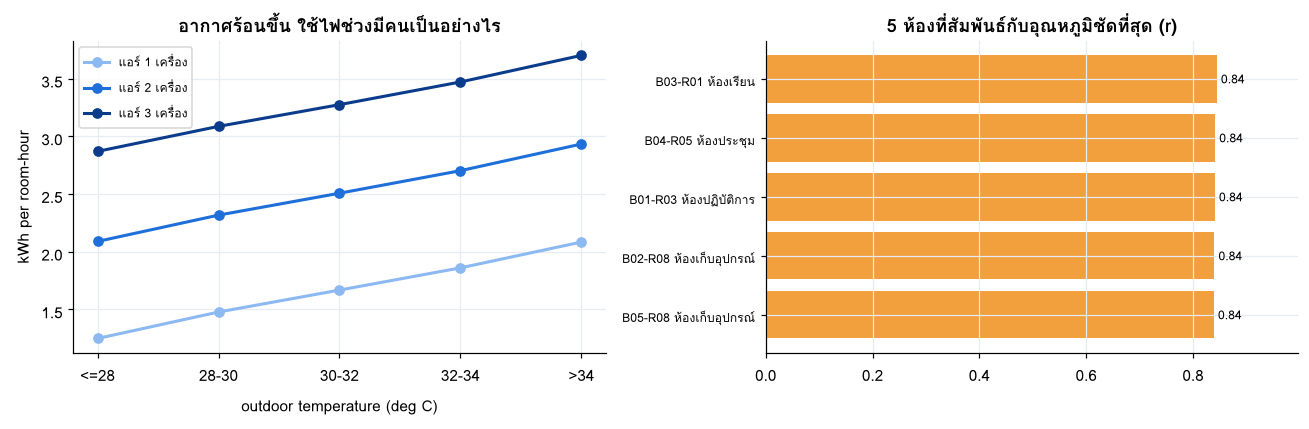

average room correlation by building (outdoor weather is one series for all buildings):


,mean_r_temp
building_name,
อาคารปฏิบัติการ,0.748
อาคารเรียน 1,0.740
อาคารบริการ,0.726
อาคารสำนักงาน,0.711
อาคารเรียน 2,0.706


> **สรุปสั้น (n=93960):** พบความสัมพันธ์: อากาศร้อนขึ้น 1 องศา ใช้ไฟช่วงมีคนเพิ่มประมาณ 0.099 kWh ต่อห้องต่อชั่วโมง (ควบคุมห้อง ความชื้น จำนวนคนแล้ว)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** สหสัมพันธ์อุณหภูมิกับไฟ 0.46 (ทุกชั่วโมง) 0.34 (ช่วงมีคน) 0.71 (ในห้องเดียวกัน) ความชื้นกับไฟ -0.39 (ค่าลบ) แต่ความชื้นสัมพันธ์กับอุณหภูมิ -0.83 เมื่อใส่อุณหภูมิในสมการร่วมกัน ความสัมพันธ์ของความชื้นหายไป (ผลเหลือใกล้ศูนย์ p=0.924) ห้องที่สัมพันธ์กับอุณหภูมิชัดสุดคือ B03-R01 (r=0.84) อาคารที่เฉลี่ยสูงสุดคือ อาคารปฏิบัติการ

**💡 ความหมาย:** พบแนวโน้มที่อากาศร้อนสัมพันธ์กับการใช้ไฟมากขึ้นในช่วงมีคน แต่ข้อมูลนี้บอกสาเหตุไม่ได้ ความชื้นและอุณหภูมิเคลื่อนไหวสวนทางกัน (-0.83) ความชื้นที่ดูเหมือนสัมพันธ์กับไฟน่าจะสะท้อนอุณหภูมิ ไม่ใช่ผลของความชื้นเอง อากาศมีชุดเดียวทุกอาคาร จึงเทียบความต่างของอาคารด้านอากาศไม่ได้ ตัวเลขรายห้องแสดงเพียงความสัมพันธ์ในห้องนั้น

**🎯 ข้อเสนอแนะ:** วางแผนตั้งอุณหภูมิแอร์และตรวจฟิลเตอร์ก่อนช่วงอากาศร้อน (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่ ก่อนเดือนที่ร้อนสุด) และเก็บข้อมูลหลายปีเพื่อยืนยัน

- ใช้ดูอะไร: ดูว่าอากาศร้อนหรือชื้นสัมพันธ์กับการใช้ไฟหรือไม่
- อ่านอย่างไร: กราฟซ้ายเส้นที่ชันขึ้นแปลว่าอากาศร้อนขึ้นไฟเพิ่ม แยกสีตามจำนวนแอร์ กราฟขวาแท่งยาวคือห้องที่สัมพันธ์ชัด
- วิเคราะห์ด้วยวิธี: สหสัมพันธ์ก่อนและหลังควบคุมช่วงเวลา/ห้อง และถดถอยเชิงเส้นพร้อมตัวแปรห้อง (ตัวคุมค่าเฉพาะห้อง)

</details>

In [14]:
# temperature / humidity vs kWh: pooled vs controlled
occ = df[~OFF].copy()
cor2 = pd.DataFrame({
    "all hours": [r(E, "temperature_c", df), r(E, "relative_humidity_percent", df), r("temperature_c", "relative_humidity_percent", df)],
    "occupied hours only": [r(E, "temperature_c", occ), r(E, "relative_humidity_percent", occ), r("temperature_c", "relative_humidity_percent", occ)],
    "occupied hours, within each room": [within(occ, E, "temperature_c", "room_id"), within(occ, E, "relative_humidity_percent", "room_id"), np.nan]},
    index=["energy vs temperature", "energy vs humidity", "temperature vs humidity"])
display(cor2.round(3))

mod2 = smf.ols(E + " ~ temperature_c + relative_humidity_percent + occupancy_people + C(room_id)", data=occ).fit(cov_type="HC1")
coef = pd.DataFrame({"effect_kwh_per_unit": mod2.params, "p_value": mod2.pvalues}).loc[["temperature_c", "relative_humidity_percent", "occupancy_people"]]
display(coef.round(4)); print("R-squared: %.3f | n=%d" % (mod2.rsquared, int(mod2.nobs)))

occ["temp_bin"] = pd.cut(occ["temperature_c"], [0, 28, 30, 32, 34, 40], labels=["<=28", "28-30", "30-32", "32-34", ">34"])
tb = occ.groupby(["temp_bin", "air_conditioner_count"], observed=True)[E].agg(["mean", "size"]).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, col in zip([1, 2, 3], [BLUE_L, BLUE, BLUE_D]):
    s = tb[tb["air_conditioner_count"] == k]
    ax[0].plot(s["temp_bin"].astype(str), s["mean"], marker="o", color=col, lw=2, label="แอร์ %d เครื่อง" % k)
ax[0].set_title("อากาศร้อนขึ้น ใช้ไฟช่วงมีคนเป็นอย่างไร"); ax[0].set_xlabel("outdoor temperature (deg C)"); ax[0].set_ylabel("kWh per room-hour"); ax[0].legend(fontsize=8)

# which rooms show the clearest relationship with temperature (occupied hours)
rc = pd.Series({rid: d[E].corr(d["temperature_c"]) for rid, d in occ.groupby("room_id")}, name="r_temp").to_frame().join(room.set_index("room_id")[["building_name", "room_type", "ac_count"]])
top_rc = rc.sort_values("r_temp", ascending=False).head(5)
hbar(ax[1], top_rc.index + " " + top_rc["room_type"], top_rc["r_temp"], ORANGE, fmt="%.2f"); ax[1].set_title("5 ห้องที่สัมพันธ์กับอุณหภูมิชัดที่สุด (r)")
ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
rb = rc.groupby("building_name")["r_temp"].mean().sort_values(ascending=False)
print("average room correlation by building (outdoor weather is one series for all buildings):"); display(rb.round(3).to_frame("mean_r_temp"))
explain(
    short="พบความสัมพันธ์: อากาศร้อนขึ้น 1 องศา ใช้ไฟช่วงมีคนเพิ่มประมาณ %.3f kWh ต่อห้องต่อชั่วโมง (ควบคุมห้อง ความชื้น จำนวนคนแล้ว)" % coef.loc["temperature_c", "effect_kwh_per_unit"],
    found="สหสัมพันธ์อุณหภูมิกับไฟ %.2f (ทุกชั่วโมง) %.2f (ช่วงมีคน) %.2f (ในห้องเดียวกัน) ความชื้นกับไฟ %.2f (ค่าลบ) แต่ความชื้นสัมพันธ์กับอุณหภูมิ %.2f เมื่อใส่อุณหภูมิในสมการร่วมกัน ความสัมพันธ์ของความชื้นหายไป (ผลเหลือใกล้ศูนย์ %s) ห้องที่สัมพันธ์กับอุณหภูมิชัดสุดคือ %s (r=%.2f) อาคารที่เฉลี่ยสูงสุดคือ %s" % (cor2.iloc[0, 0], cor2.iloc[0, 1], cor2.iloc[0, 2], cor2.iloc[1, 0], cor2.iloc[2, 0], pf(coef.loc["relative_humidity_percent", "p_value"]), top_rc.index[0], top_rc.iloc[0]["r_temp"], rb.index[0]),
    meaning="พบแนวโน้มที่อากาศร้อนสัมพันธ์กับการใช้ไฟมากขึ้นในช่วงมีคน แต่ข้อมูลนี้บอกสาเหตุไม่ได้ ความชื้นและอุณหภูมิเคลื่อนไหวสวนทางกัน (%.2f) ความชื้นที่ดูเหมือนสัมพันธ์กับไฟน่าจะสะท้อนอุณหภูมิ ไม่ใช่ผลของความชื้นเอง อากาศมีชุดเดียวทุกอาคาร จึงเทียบความต่างของอาคารด้านอากาศไม่ได้ ตัวเลขรายห้องแสดงเพียงความสัมพันธ์ในห้องนั้น" % cor2.iloc[2, 0],
    action="วางแผนตั้งอุณหภูมิแอร์และตรวจฟิลเตอร์ก่อนช่วงอากาศร้อน (ผู้รับผิดชอบ: ฝ่ายอาคารสถานที่ ก่อนเดือนที่ร้อนสุด) และเก็บข้อมูลหลายปีเพื่อยืนยัน",
    use="ดูว่าอากาศร้อนหรือชื้นสัมพันธ์กับการใช้ไฟหรือไม่", read="กราฟซ้ายเส้นที่ชันขึ้นแปลว่าอากาศร้อนขึ้นไฟเพิ่ม แยกสีตามจำนวนแอร์ กราฟขวาแท่งยาวคือห้องที่สัมพันธ์ชัด",
    method="สหสัมพันธ์ก่อนและหลังควบคุมช่วงเวลา/ห้อง และถดถอยเชิงเส้นพร้อมตัวแปรห้อง (ตัวคุมค่าเฉพาะห้อง)", n=int(mod2.nobs))

## 2.9 วันทำการกับวันหยุดต่างกันอย่างไร

,hours,total_kwh,mean_kwh_h,share_of_kwh_pct
day_type_th,,,,
วันทำการ,250560,262493.19,1.05,95.54
วันหยุด,99840,12255.15,0.12,4.46


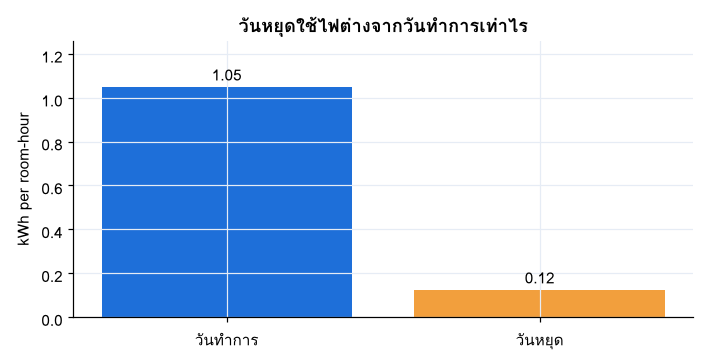

> **สรุปสั้น (n=350400):** วันหยุดใช้ไฟเฉลี่ยต่อชั่วโมงต่ำกว่าวันทำการ 88% แต่ยังเป็น 4.5% ของไฟทั้งปี

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** วันทำการ 1.05 วันหยุด 0.12 kWh/ห้อง/ชม. (4.5% ของไฟทั้งปีเกิดในวันหยุด ทั้งที่เป็น 28.5% ของชั่วโมง)

**💡 ความหมาย:** ไฟวันหยุดคือฐานที่ใช้โดยไม่มีคน การลดฐานนี้ส่งผลต่อยอดทั้งปีโดยตรง

**🎯 ข้อเสนอแนะ:** ดูรายชื่อห้องที่ใช้ไฟวันหยุดสูงในหัวข้อ 2.6 ก่อน

- ใช้ดูอะไร: เทียบวันทำการกับวันหยุด
- อ่านอย่างไร: แท่งน้ำเงินคือวันทำการ แท่งส้มคือวันหยุด
- วิเคราะห์ด้วยวิธี: เฉลี่ย kWh ต่อห้องต่อชั่วโมงแยกประเภทวัน

</details>

In [15]:
# weekday vs weekend overall, with the share of kWh that falls on each
cmp_ = df.groupby("day_type_th").agg(hours=(E, "size"), total_kwh=(E, "sum"), mean_kwh_h=(E, "mean"))
cmp_["share_of_kwh_pct"] = 100 * cmp_["total_kwh"] / TOTAL
display(cmp_.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(cmp_.index, cmp_["mean_kwh_h"], color=[BLUE, ORANGE])
for i, v in enumerate(cmp_["mean_kwh_h"]):
    ax.text(i, v, "%.2f" % v, ha="center", va="bottom")
ax.set_ylim(0, cmp_["mean_kwh_h"].max() * 1.2); ax.set_title("วันหยุดใช้ไฟต่างจากวันทำการเท่าไร"); ax.set_ylabel("kWh per room-hour")
plt.tight_layout(); plt.show()
dd = 100 * (cmp_.loc["วันหยุด", "mean_kwh_h"] / cmp_.loc["วันทำการ", "mean_kwh_h"] - 1)
explain(
    short="วันหยุดใช้ไฟเฉลี่ยต่อชั่วโมงต่ำกว่าวันทำการ %.0f%% แต่ยังเป็น %.1f%% ของไฟทั้งปี" % (-dd, cmp_.loc["วันหยุด", "share_of_kwh_pct"]),
    found="วันทำการ %.2f วันหยุด %.2f kWh/ห้อง/ชม. (%.1f%% ของไฟทั้งปีเกิดในวันหยุด ทั้งที่เป็น %.1f%% ของชั่วโมง)" % (cmp_.loc["วันทำการ", "mean_kwh_h"], cmp_.loc["วันหยุด", "mean_kwh_h"], cmp_.loc["วันหยุด", "share_of_kwh_pct"], 100 * cmp_.loc["วันหยุด", "hours"] / N_ROWS),
    meaning="ไฟวันหยุดคือฐานที่ใช้โดยไม่มีคน การลดฐานนี้ส่งผลต่อยอดทั้งปีโดยตรง",
    action="ดูรายชื่อห้องที่ใช้ไฟวันหยุดสูงในหัวข้อ 2.6 ก่อน", use="เทียบวันทำการกับวันหยุด", read="แท่งน้ำเงินคือวันทำการ แท่งส้มคือวันหยุด",
    method="เฉลี่ย kWh ต่อห้องต่อชั่วโมงแยกประเภทวัน", n=N_ROWS)

# ขั้นที่ 3 ค่าผิดปกติและค่าว่าง

## 3.1 ค่าผิดปกติ: ที่ไหน เมื่อไร บ่อยแค่ไหน

outliers: 21 | rooms affected: 21 | max per room: 1


,room_id,building_id,room_type,count
0,B01-R01,B01,ห้องเรียน,1
1,B01-R04,B01,สำนักงาน,1
2,B01-R07,B01,ห้องเรียน,1
3,B01-R08,B01,ห้องเก็บอุปกรณ์,1
4,B02-R03,B02,ห้องปฏิบัติการ,1
5,B02-R04,B02,สำนักงาน,1
6,B02-R06,B02,ห้องสมุด,1
7,B02-R07,B02,ห้องเรียน,1


,top5_raw,top5_clean
0,B02-R02,B02-R02
1,B03-R05,B03-R05
2,B04-R02,B04-R02
3,B01-R04,B01-R04
4,B04-R06,B04-R06


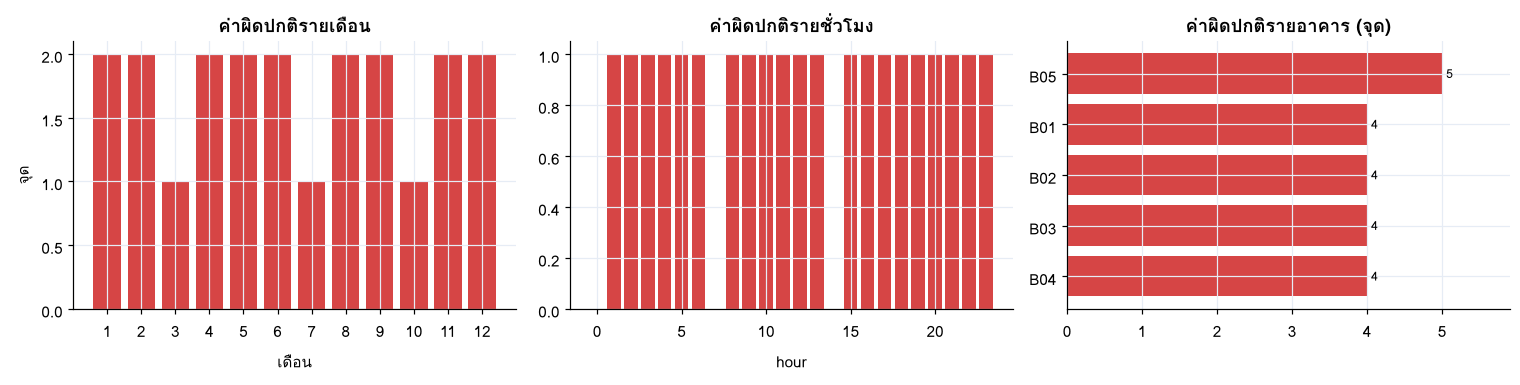

> **สรุปสั้น (n=21):** พบ 21 จุด (0.0060% ของข้อมูล) กระจายใน 21 ห้อง ห้องละไม่เกิน 1 จุด ผลต่อยอดรวม 0.17%

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ค่าผิดปกติเกิดทั้งหมด 21 ครั้ง แต่ละครั้งเป็นชั่วโมงเดียวโดดๆ สูงกว่าปกติ 24-34 เท่า กระจายหลายเดือน หลายชั่วโมง ไม่มีห้องใดเด่นกว่า (ห้องละ 1 จุด จึงจัดอันดับตามจำนวนไม่ได้) 5 ห้องที่ใช้ไฟรวมสูงสุดเมื่อเทียบก่อน-หลังจัดการค่าผิดปกติ: ไม่เปลี่ยน

**💡 ความหมาย:** ลักษณะเข้าได้กับการอ่านค่าผิดพลาดมากกว่าพฤติกรรมการใช้ไฟ แต่ข้อมูลยืนยันไม่ได้ จึงเก็บค่าเดิมไว้ ไม่ลบทิ้ง ผลจัดอันดับในหัวข้อ 2.3 ไม่ถูกบิดเบือนด้วยค่าเหล่านี้

**🎯 ข้อเสนอแนะ:** ให้ผู้ดูแลมิเตอร์ตรวจตามวันเวลาในตาราง outliers_log.csv ถ้ายืนยันเป็นเหตุการณ์จริงให้ใส่ค่าเดิมกลับ (ภายใน 2 สัปดาห์)

- ใช้ดูอะไร: ดูว่าค่าผิดปกติเกิดที่ไหน เมื่อไร บ่อยแค่ไหน
- อ่านอย่างไร: กราฟซ้ายและกลางคือจำนวนครั้งตามเดือนและชั่วโมง กราฟขวาตามอาคาร
- วิเคราะห์ด้วยวิธี: เทียบแต่ละค่ากับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x ประเภทวัน) และเทียบอันดับก่อนหลัง

</details>

In [16]:
# where / when / how often (from the cleaning step). raw values are kept in outliers_log.csv
by_room = out_log.groupby(["room_id", "building_id", "room_type"]).size().sort_values(ascending=False).reset_index(name="count")
by_b = out_log.groupby("building_id").size().sort_values(ascending=False)
by_m = out_log.groupby(out_log["timestamp"].dt.month).size().reindex(range(1, 13), fill_value=0)
by_h = out_log.groupby(out_log["timestamp"].dt.hour).size().reindex(range(24), fill_value=0)
print("outliers:", len(out_log), "| rooms affected:", by_room.shape[0], "| max per room:", int(by_room["count"].max()))
display(by_room.head(8))

# does the cleaning step change the rankings? compare top-5 rooms with raw spikes kept vs cleaned
raw_tot = df.groupby("room_id")["energy_kwh"].sum().sort_values(ascending=False)
cl_tot = df.groupby("room_id")[E].sum().sort_values(ascending=False)
rk = pd.DataFrame({"top5_raw": raw_tot.head(5).index, "top5_clean": cl_tot.head(5).index})
display(rk)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(by_m.index, by_m.values, color=RED); ax[0].set_title("ค่าผิดปกติรายเดือน"); ax[0].set_xlabel("เดือน"); ax[0].set_ylabel("จุด"); ax[0].set_xticks(range(1, 13))
ax[1].bar(by_h.index, by_h.values, color=RED); ax[1].set_title("ค่าผิดปกติรายชั่วโมง"); ax[1].set_xlabel("hour")
hbar(ax[2], by_b.index, by_b.values, RED, fmt="%d"); ax[2].set_title("ค่าผิดปกติรายอาคาร (จุด)")
plt.tight_layout(); plt.show()
impact_kwh = (out_log["value_kwh"] - out_log["normal_kwh"]).sum()
explain(
    short="พบ %d จุด (%.4f%% ของข้อมูล) กระจายใน %d ห้อง ห้องละไม่เกิน %d จุด ผลต่อยอดรวม %.2f%%" % (len(out_log), 100 * len(out_log) / N_ROWS, by_room.shape[0], by_room["count"].max(), 100 * impact_kwh / TOTAL),
    found="ค่าผิดปกติเกิดทั้งหมด %d ครั้ง แต่ละครั้งเป็นชั่วโมงเดียวโดดๆ สูงกว่าปกติ %.0f-%.0f เท่า กระจายหลายเดือน หลายชั่วโมง ไม่มีห้องใดเด่นกว่า (ห้องละ %d จุด จึงจัดอันดับตามจำนวนไม่ได้) 5 ห้องที่ใช้ไฟรวมสูงสุดเมื่อเทียบก่อน-หลังจัดการค่าผิดปกติ: %s" % (len(out_log), out_log["ratio_to_normal"].min(), out_log["ratio_to_normal"].max(), by_room["count"].max(), "ไม่เปลี่ยน" if list(rk["top5_raw"]) == list(rk["top5_clean"]) else "เปลี่ยน"),
    meaning="ลักษณะเข้าได้กับการอ่านค่าผิดพลาดมากกว่าพฤติกรรมการใช้ไฟ แต่ข้อมูลยืนยันไม่ได้ จึงเก็บค่าเดิมไว้ ไม่ลบทิ้ง ผลจัดอันดับในหัวข้อ 2.3 ไม่ถูกบิดเบือนด้วยค่าเหล่านี้",
    action="ให้ผู้ดูแลมิเตอร์ตรวจตามวันเวลาในตาราง outliers_log.csv ถ้ายืนยันเป็นเหตุการณ์จริงให้ใส่ค่าเดิมกลับ (ภายใน 2 สัปดาห์)",
    use="ดูว่าค่าผิดปกติเกิดที่ไหน เมื่อไร บ่อยแค่ไหน", read="กราฟซ้ายและกลางคือจำนวนครั้งตามเดือนและชั่วโมง กราฟขวาตามอาคาร",
    method="เทียบแต่ละค่ากับกลุ่มของตัวเอง (มิเตอร์ x ชั่วโมง x ประเภทวัน) และเทียบอันดับก่อนหลัง", n=len(out_log))

## 3.2 ค่าว่าง: รูปแบบการขาดหาย

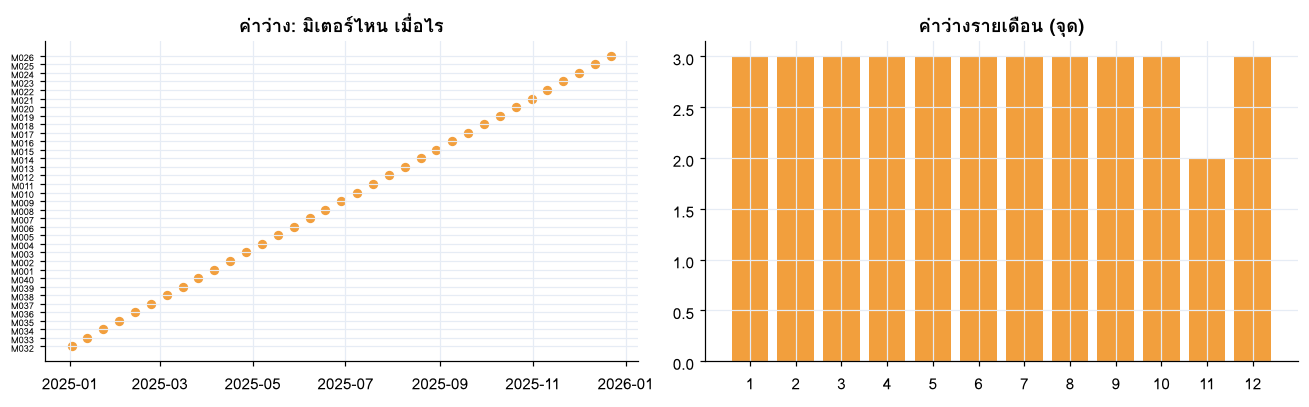

> **สรุปสั้น (n=35):** ค่าว่าง 35 จุด (0.0100%) ห้องละไม่เกิน 1 จุด ไม่พบการขาดพร้อมกันหลายมิเตอร์ (ชั่วโมงเดียวกันขาดไม่เกิน 1 มิเตอร์)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ค่าว่างกระจายใน 35 ห้อง ไม่มีห้องใดขาดต่อเนื่อง และไม่มีชั่วโมงที่หลายมิเตอร์ขาดพร้อมกัน แสดงว่าไม่ใช่ระบบรวมล่ม

**💡 ความหมาย:** เติมด้วยค่ากลางของช่วงเวลาเดียวกันได้โดยไม่กระทบการจัดอันดับ (ยอดรวมเปลี่ยนเพียงเล็กน้อยตามบันทึกกระทบยอด)

**🎯 ข้อเสนอแนะ:** ตรวจสาเหตุที่แต่ละมิเตอร์ขาดข้อมูลเป็นครั้งคราว (ผู้ดูแลระบบมิเตอร์ ภายใน 1 เดือน)

- ใช้ดูอะไร: ดูรูปแบบการขาดหาย
- อ่านอย่างไร: จุดส้มแต่ละจุดคือ 1 ชั่วโมงที่ไม่มีค่า
- วิเคราะห์ด้วยวิธี: นับค่าว่างตามห้อง เดือน และเวลาเดียวกัน ตรวจการขาดร่วมกัน

</details>

In [17]:
# missing pattern from the flags set in the cleaning step
na = df[df["flag_missing"]]
co = na.groupby("timestamp").size()
per_room_na = na.groupby("room_id").size()
by_month = na.groupby("month").size().reindex(range(1, 13), fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(na["timestamp"], na["meter_id"], color=ORANGE, s=26); ax[0].tick_params(axis="y", labelsize=6)
ax[0].set_title("ค่าว่าง: มิเตอร์ไหน เมื่อไร")
ax[1].bar(by_month.index, by_month.values, color=ORANGE); ax[1].set_title("ค่าว่างรายเดือน (จุด)"); ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
explain(
    short="ค่าว่าง %d จุด (%.4f%%) ห้องละไม่เกิน %d จุด ไม่พบการขาดพร้อมกันหลายมิเตอร์ (ชั่วโมงเดียวกันขาดไม่เกิน %d มิเตอร์)" % (len(na), 100 * len(na) / N_ROWS, per_room_na.max(), co.max()),
    found="ค่าว่างกระจายใน %d ห้อง ไม่มีห้องใดขาดต่อเนื่อง และไม่มีชั่วโมงที่หลายมิเตอร์ขาดพร้อมกัน แสดงว่าไม่ใช่ระบบรวมล่ม" % per_room_na.size,
    meaning="เติมด้วยค่ากลางของช่วงเวลาเดียวกันได้โดยไม่กระทบการจัดอันดับ (ยอดรวมเปลี่ยนเพียงเล็กน้อยตามบันทึกกระทบยอด)",
    action="ตรวจสาเหตุที่แต่ละมิเตอร์ขาดข้อมูลเป็นครั้งคราว (ผู้ดูแลระบบมิเตอร์ ภายใน 1 เดือน)",
    use="ดูรูปแบบการขาดหาย", read="จุดส้มแต่ละจุดคือ 1 ชั่วโมงที่ไม่มีค่า",
    method="นับค่าว่างตามห้อง เดือน และเวลาเดียวกัน ตรวจการขาดร่วมกัน", n=len(na))

# ขั้นที่ 4 ตอบโจทย์ และ Insight

## 4.1 ปัญหาและแนวทางแก้ไข จัดลำดับความรุนแรง

,id,problem,where,excess_kwh_per_year,impact_pct_of_campus,certainty,severity,owner,timeframe
0,P1,ใช้ไฟสูงผิดปกติช่วง 18:00-22:59 น. ทั้งที่ไม่มีคน,"B02-R02, B03-R05, B04-R05",7116.6,2.590,สูง,สูง,ฝ่ายอาคารสถานที่,1 สัปดาห์
1,P2,ใช้ไฟต่อเนื่องตลอดวันในช่วงไม่มีคน (ห้องคอมพิว...,"B01-R02, B02-R02, B03-R02, B04-R02, B05-R02",5768.6,2.100,กลาง,กลาง,ผู้ดูแลห้องคอมพิวเตอร์,1 เดือน
2,P3,ค่าสูงผิดปกติรายชั่วโมง (21 จุด),21 ห้อง (ดู outliers_log.csv),468.5,0.171,กลาง,ต่ำ,ผู้ดูแลมิเตอร์,2 สัปดาห์
3,P4,"คุณภาพการบันทึกข้อมูล (ซ้ำ 100, ว่าง 35, ติดลบ...","มิเตอร์ M001, M009, M017, M025, M033 (ซ้ำ) และ...",0.0,0.000,สูง,ต่ำ,ผู้ดูแลระบบมิเตอร์,1 เดือน


severity levels used: {'ต่ำ': 2, 'สูง': 1, 'กลาง': 1}


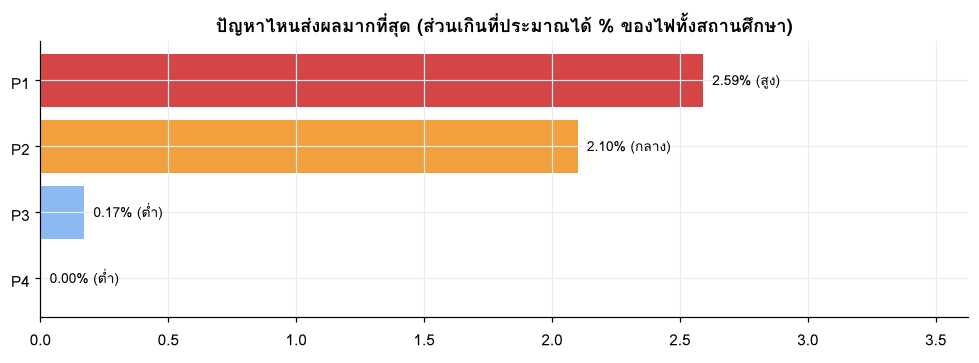

> **สรุปสั้น (n=40):** ปัญหาสูง 1 ข้อ กลาง 1 ข้อ ต่ำ 2 ข้อ ส่วนเกินที่ประมาณได้รวม 13,354 kWh ต่อปี (4.9% ของทั้งหมด)

<details><summary><b>▶ ดูรายละเอียดการวิเคราะห์ (กดเปิด/ปิด)</b></summary>

**🔍 สิ่งที่พบ:** ปัญหาที่ส่งผลมากสุดคือ P1 ใช้ไฟสูงผิดปกติช่วง 18:00-22:59 น. ทั้งที่ไม่มีคน (7,117 kWh หรือ 2.59%) ที่ห้อง B02-R02, B03-R05, B04-R05

**💡 ความหมาย:** ความรุนแรงมาจากสองด้านรวมกัน คือผลกระทบ (ส่วนเกินเทียบทั้งสถานศึกษา) และความแน่นอนว่าเป็นปัญหาจริง ปัญหาที่อาจเป็นการใช้งานจำเป็นถูกลดระดับลง 1 ขั้น เกณฑ์ที่ใช้เป็นค่าตั้งต้น ส่วนเกินคือการประมาณเทียบกับค่าปกติของห้องอื่น ไม่ใช่ค่าที่วัดได้โดยตรง

**🎯 ข้อเสนอแนะ:** เรียงตามตาราง: ทำข้อสูงก่อนภายใน 1 สัปดาห์ แล้วตรวจผลโดยดูข้อมูลหลังแก้ไข

- ใช้ดูอะไร: จัดลำดับว่าควรแก้อะไรก่อน
- อ่านอย่างไร: แท่งยาวส่งผลมาก สีแดง=สูง ส้ม=กลาง ฟ้า=ต่ำ
- วิเคราะห์ด้วยวิธี: ส่วนเกิน = kWh ที่ใช้เกินค่าปกติของช่วงเวลาเดียวกัน เทียบ kWh ทั้งหมด ลดระดับถ้าไม่แน่ใจสาเหตุ

</details>

In [18]:
# severity = impact (estimated excess kWh as % of campus total) x certainty. DEFAULT thresholds are in THR.
def tier_from_impact(p):
    return "สูง" if p >= THR["impact_high_pct"] else ("กลาง" if p >= THR["impact_mid_pct"] else "ต่ำ")
def lower(t):
    return {"สูง": "กลาง", "กลาง": "ต่ำ", "ต่ำ": "ต่ำ"}[t]

ev = room[room["flag_evening_block"]]
bs = room[room["flag_continuous_baseline"]]
dup_kwh_total = pd.read_csv(CLEAN + "reconciliation.csv", encoding="utf-8-sig")
dq_rows = int(df["flag_missing"].sum() + df["flag_negative"].sum()) + 100
probs = []
def add(pid, title, where, excess, certainty, why_cert, action, owner, when):
    pct = 100 * excess / TOTAL
    t = tier_from_impact(pct)
    sev = t if certainty == "สูง" else lower(t)
    probs.append({"id": pid, "problem": title, "where": where, "excess_kwh_per_year": round(excess, 1), "impact_pct_of_campus": round(pct, 3),
                  "certainty": certainty, "certainty_reason": why_cert, "severity": sev, "action": action, "owner": owner, "timeframe": when})
add("P1", "ใช้ไฟสูงผิดปกติช่วง 18:00-22:59 น. ทั้งที่ไม่มีคน", ", ".join(ev["room_id"]), ev["evening_excess_kwh"].sum(), "สูง",
    "จำนวนคนเป็น 0 ทุกชั่วโมงที่พบ และเกิดซ้ำทุกวันทุกเดือน", "ตรวจการตั้งเวลา/สถานะอุปกรณ์หลัง 18:00 น. แล้วเทียบผลก่อน-หลัง", "ฝ่ายอาคารสถานที่", "1 สัปดาห์")
add("P2", "ใช้ไฟต่อเนื่องตลอดวันในช่วงไม่มีคน (ห้องคอมพิวเตอร์)", ", ".join(bs["room_id"]), bs["baseline_excess_kwh"].sum(), "กลาง",
    "อาจเป็นอุปกรณ์ที่ต้องเปิดตลอดเวลา ข้อมูลไม่ระบุอุปกรณ์", "สอบถามผู้ดูแลห้องว่าอุปกรณ์ใดต้องเปิดตลอด ที่ไม่จำเป็นให้ตั้งเวลาปิด", "ผู้ดูแลห้องคอมพิวเตอร์", "1 เดือน")
add("P3", "ค่าสูงผิดปกติรายชั่วโมง (%d จุด)" % len(out_log), "%d ห้อง (ดู outliers_log.csv)" % by_room.shape[0], impact_kwh, "กลาง",
    "เป็นได้ทั้งการอ่านค่าผิดพลาดและเหตุการณ์จริง ยืนยันจากข้อมูลไม่ได้", "ตรวจมิเตอร์ตามวันเวลาในตาราง ถ้าเป็นเหตุการณ์จริงใส่ค่ากลับ", "ผู้ดูแลมิเตอร์", "2 สัปดาห์")
dq_excess = TOTAL * 0.0001
add("P4", "คุณภาพการบันทึกข้อมูล (ซ้ำ 100, ว่าง %d, ติดลบ %d)" % (int(df["flag_missing"].sum()), int(df["flag_negative"].sum())), "มิเตอร์ M001, M009, M017, M025, M033 (ซ้ำ) และทุกมิเตอร์ (ว่าง/ติดลบ)",
    0.0, "สูง", "นับจากข้อมูลโดยตรง", "แก้ระบบบันทึกให้ไม่ซ้ำ ไม่ส่งค่า -0.5 และแจ้งเตือนเมื่อขาด", "ผู้ดูแลระบบมิเตอร์", "1 เดือน")
prob = pd.DataFrame(probs)
order = {"สูง": 0, "กลาง": 1, "ต่ำ": 2}
prob = prob.sort_values(["severity", "impact_pct_of_campus"], key=lambda s: s.map(order) if s.name == "severity" else -s).reset_index(drop=True)
display(prob[["id", "problem", "where", "excess_kwh_per_year", "impact_pct_of_campus", "certainty", "severity", "owner", "timeframe"]])
print("severity levels used:", prob["severity"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(9, 3.4))
colors = {"สูง": RED, "กลาง": ORANGE, "ต่ำ": BLUE_L}
ax.barh(prob["id"][::-1], prob["impact_pct_of_campus"][::-1], color=[colors[s] for s in prob["severity"][::-1]])
for i, (v, s) in enumerate(zip(prob["impact_pct_of_campus"][::-1], prob["severity"][::-1])):
    ax.text(v, i, "  %.2f%% (%s)" % (v, s), va="center", fontsize=9)
ax.set_xlim(0, max(prob["impact_pct_of_campus"].max() * 1.4, 1)); ax.set_title("ปัญหาไหนส่งผลมากที่สุด (ส่วนเกินที่ประมาณได้ % ของไฟทั้งสถานศึกษา)")
plt.tight_layout(); plt.show()
explain(
    short="ปัญหาสูง %d ข้อ กลาง %d ข้อ ต่ำ %d ข้อ ส่วนเกินที่ประมาณได้รวม %s kWh ต่อปี (%.1f%% ของทั้งหมด)" % ((prob["severity"] == "สูง").sum(), (prob["severity"] == "กลาง").sum(), (prob["severity"] == "ต่ำ").sum(), format(round(prob["excess_kwh_per_year"].sum()), ","), prob["impact_pct_of_campus"].sum()),
    found="ปัญหาที่ส่งผลมากสุดคือ %s (%s kWh หรือ %.2f%%) ที่ห้อง %s" % (prob.iloc[0]["id"] + " " + prob.iloc[0]["problem"], format(round(prob.iloc[0]["excess_kwh_per_year"]), ","), prob.iloc[0]["impact_pct_of_campus"], prob.iloc[0]["where"]),
    meaning="ความรุนแรงมาจากสองด้านรวมกัน คือผลกระทบ (ส่วนเกินเทียบทั้งสถานศึกษา) และความแน่นอนว่าเป็นปัญหาจริง ปัญหาที่อาจเป็นการใช้งานจำเป็นถูกลดระดับลง 1 ขั้น เกณฑ์ที่ใช้เป็นค่าตั้งต้น ส่วนเกินคือการประมาณเทียบกับค่าปกติของห้องอื่น ไม่ใช่ค่าที่วัดได้โดยตรง",
    action="เรียงตามตาราง: ทำข้อสูงก่อนภายใน 1 สัปดาห์ แล้วตรวจผลโดยดูข้อมูลหลังแก้ไข",
    use="จัดลำดับว่าควรแก้อะไรก่อน", read="แท่งยาวส่งผลมาก สีแดง=สูง ส้ม=กลาง ฟ้า=ต่ำ",
    method="ส่วนเกิน = kWh ที่ใช้เกินค่าปกติของช่วงเวลาเดียวกัน เทียบ kWh ทั้งหมด ลดระดับถ้าไม่แน่ใจสาเหตุ", n=N_ROOMS)

## 4.2 สรุป Insight ที่นำไปใช้ได้

In [19]:
# insights: each has a number from this run and a next step
top_prob = prob.iloc[0]
ins = [
 ("ไฟช่วงเย็นนอกเวลาเป็นจุดแรกที่ควรตรวจ", "ห้อง %s ใช้ไฟสูงผิดปกติช่วงเย็นโดยไม่มีคน ส่วนเกินประมาณ %s kWh/ปี (%.2f%% ของทั้งหมด)" % (top_prob["where"], format(round(top_prob["excess_kwh_per_year"]), ","), top_prob["impact_pct_of_campus"]), "ตรวจห้องเหล่านี้ภายใน 1 สัปดาห์"),
 ("ห้องคอมพิวเตอร์มีฐานการใช้ไฟต่อเนื่อง", "ค่ากลาง %.2f kWh/ชม. ช่วงไม่มีคน เทียบห้องอื่น %.3f (%.1f เท่า) อาจมีการใช้พลังงานจากอุปกรณ์ที่ทำงานต่อเนื่อง" % (comp["other_off_mean_kwh_h"].median(), others["other_off_mean_kwh_h"].median(), ratio_c), "สอบถามผู้ดูแลก่อนตั้งเวลาปิด"),
 ("แอร์อธิบายการใช้ไฟได้ชัดกว่าจำนวนคน", "ห้องแอร์ 1/2/3 เครื่องใช้ไฟช่วงมีคน %s kWh/ชม." % " / ".join("%.2f" % v for v in by_ac["mean_kwh"]), "เปรียบเทียบห้องกับห้องที่มีแอร์เท่ากัน"),
 ("อากาศร้อนสัมพันธ์กับการใช้ไฟ", "ร้อนขึ้น 1 องศา ไฟช่วงมีคนเพิ่มประมาณ %.3f kWh/ห้อง/ชม. (พบความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ)" % coef.loc["temperature_c", "effect_kwh_per_unit"], "เตรียมตั้งค่าแอร์ก่อนฤดูร้อน"),
 ("วันหยุดยังมีฐานการใช้ไฟ", "วันหยุดเป็น %.1f%% ของไฟทั้งปี ทั้งที่ไม่มีคนใช้งาน" % cmp_.loc["วันหยุด", "share_of_kwh_pct"], "ตั้งเวลาปิดอุปกรณ์วันหยุด"),
]
for i, (h, f, a) in enumerate(ins, 1):
    md("**%d. %s**  \nพบว่า: %s  \nแล้วทำอะไรต่อ: %s" % (i, h, f, a))
md("**ข้อจำกัด:** ข้อมูลปีเดียว (ยืนยันไม่ได้ว่าค่าไฟสูงขึ้นเทียบปีก่อน) | เป็นข้อมูลจำลอง | ไม่มีอัตราค่าไฟ จึงรายงานเป็น kWh | ส่วนเกินเป็นค่าประมาณ")

**1. ไฟช่วงเย็นนอกเวลาเป็นจุดแรกที่ควรตรวจ**  
พบว่า: ห้อง B02-R02, B03-R05, B04-R05 ใช้ไฟสูงผิดปกติช่วงเย็นโดยไม่มีคน ส่วนเกินประมาณ 7,117 kWh/ปี (2.59% ของทั้งหมด)  
แล้วทำอะไรต่อ: ตรวจห้องเหล่านี้ภายใน 1 สัปดาห์

**2. ห้องคอมพิวเตอร์มีฐานการใช้ไฟต่อเนื่อง**  
พบว่า: ค่ากลาง 0.26 kWh/ชม. ช่วงไม่มีคน เทียบห้องอื่น 0.080 (3.2 เท่า) อาจมีการใช้พลังงานจากอุปกรณ์ที่ทำงานต่อเนื่อง  
แล้วทำอะไรต่อ: สอบถามผู้ดูแลก่อนตั้งเวลาปิด

**3. แอร์อธิบายการใช้ไฟได้ชัดกว่าจำนวนคน**  
พบว่า: ห้องแอร์ 1/2/3 เครื่องใช้ไฟช่วงมีคน 1.73 / 2.58 / 3.34 kWh/ชม.  
แล้วทำอะไรต่อ: เปรียบเทียบห้องกับห้องที่มีแอร์เท่ากัน

**4. อากาศร้อนสัมพันธ์กับการใช้ไฟ**  
พบว่า: ร้อนขึ้น 1 องศา ไฟช่วงมีคนเพิ่มประมาณ 0.099 kWh/ห้อง/ชม. (พบความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ)  
แล้วทำอะไรต่อ: เตรียมตั้งค่าแอร์ก่อนฤดูร้อน

**5. วันหยุดยังมีฐานการใช้ไฟ**  
พบว่า: วันหยุดเป็น 4.5% ของไฟทั้งปี ทั้งที่ไม่มีคนใช้งาน  
แล้วทำอะไรต่อ: ตั้งเวลาปิดอุปกรณ์วันหยุด

**ข้อจำกัด:** ข้อมูลปีเดียว (ยืนยันไม่ได้ว่าค่าไฟสูงขึ้นเทียบปีก่อน) | เป็นข้อมูลจำลอง | ไม่มีอัตราค่าไฟ จึงรายงานเป็น kWh | ส่วนเกินเป็นค่าประมาณ

## 4.3 ในชุดข้อมูลไม่มีอะไรบ้าง และควรเพิ่มหรือไม่

In [20]:
# what is NOT in the data (we never invent it) and whether it should be added
miss_tbl = pd.DataFrame([
 ["อัตราค่าไฟ (บาทต่อหน่วย)", "รายงานเป็นเงินบาทไม่ได้ ตอนนี้ได้เฉพาะ kWh", "ควรเพิ่ม", "ฝ่ายการเงิน"],
 ["ข้อมูลปีก่อนหน้า", "ยืนยันไม่ได้ว่า ค่าไฟสูงขึ้น และแยกฤดูกาลกับการเพิ่มจริงไม่ได้", "ควรเพิ่มมาก", "ฝ่ายอาคารสถานที่"],
 ["ปฏิทินวันหยุดและตารางการใช้ห้อง", "วันหยุด = เสาร์-อาทิตย์เท่านั้น แยกวันหยุดพิเศษและช่วงปิดเทอมไม่ได้", "ควรเพิ่ม", "ฝ่ายวิชาการ"],
 ["ค่ากำลังไฟสูงสุด (kW)", "ได้เฉพาะ kWh รายชั่วโมง บอกค่าความต้องการกำลังไฟสูงสุดไม่ได้", "ควรเพิ่ม", "ผู้ดูแลมิเตอร์"],
 ["มิเตอร์แยกแอร์ ไฟแสงสว่าง เครื่องคอมพิวเตอร์", "ระบุอุปกรณ์ที่เป็นสาเหตุไม่ได้ (มิเตอร์วัดทั้งห้อง)", "ควรเพิ่ม", "ฝ่ายอาคารสถานที่"],
 ["การตั้งค่าอุณหภูมิแอร์และสถานะเปิด-ปิด", "ประเมินผลการตั้งค่าแอร์ไม่ได้", "ควรเพิ่ม", "ฝ่ายอาคารสถานที่"],
 ["สภาพอากาศรายอาคาร", "ตอนนี้อากาศชุดเดียวทุกอาคาร เทียบความต่างระหว่างอาคารด้านอากาศไม่ได้", "ไม่จำเป็น", "-"],
 ["ข้อมูลก่อน-หลังมาตรการประหยัดไฟ", "ประเมินผลของการแก้ไขไม่ได้", "ควรเพิ่มเมื่อเริ่มมาตรการ", "คณะทำงานพลังงาน"]],
 columns=["สิ่งที่ไม่มี", "ผลต่อการวิเคราะห์", "ควรเพิ่มไหม", "ผู้ที่น่าจะมีข้อมูล"])
display(miss_tbl)

,สิ่งที่ไม่มี,ผลต่อการวิเคราะห์,ควรเพิ่มไหม,ผู้ที่น่าจะมีข้อมูล
0,อัตราค่าไฟ (บาทต่อหน่วย),รายงานเป็นเงินบาทไม่ได้ ตอนนี้ได้เฉพาะ kWh,ควรเพิ่ม,ฝ่ายการเงิน
1,ข้อมูลปีก่อนหน้า,ยืนยันไม่ได้ว่า ค่าไฟสูงขึ้น และแยกฤดูกาลกับกา...,ควรเพิ่มมาก,ฝ่ายอาคารสถานที่
2,ปฏิทินวันหยุดและตารางการใช้ห้อง,วันหยุด = เสาร์-อาทิตย์เท่านั้น แยกวันหยุดพิเศ...,ควรเพิ่ม,ฝ่ายวิชาการ
3,ค่ากำลังไฟสูงสุด (kW),ได้เฉพาะ kWh รายชั่วโมง บอกค่าความต้องการกำลัง...,ควรเพิ่ม,ผู้ดูแลมิเตอร์
4,มิเตอร์แยกแอร์ ไฟแสงสว่าง เครื่องคอมพิวเตอร์,ระบุอุปกรณ์ที่เป็นสาเหตุไม่ได้ (มิเตอร์วัดทั้ง...,ควรเพิ่ม,ฝ่ายอาคารสถานที่
5,การตั้งค่าอุณหภูมิแอร์และสถานะเปิด-ปิด,ประเมินผลการตั้งค่าแอร์ไม่ได้,ควรเพิ่ม,ฝ่ายอาคารสถานที่
6,สภาพอากาศรายอาคาร,ตอนนี้อากาศชุดเดียวทุกอาคาร เทียบความต่างระหว่...,ไม่จำเป็น,-
7,ข้อมูลก่อน-หลังมาตรการประหยัดไฟ,ประเมินผลของการแก้ไขไม่ได้,ควรเพิ่มเมื่อเริ่มมาตรการ,คณะทำงานพลังงาน


## 4.4 ส่งออกตารางสรุปสำหรับแดชบอร์ด

In [21]:
# export summary tables (used later by the dashboard; all computed in this notebook)
room_out = room.copy()
room_out.round(4).to_csv(CLEAN + "room_summary.csv", index=False, encoding="utf-8-sig")
bld.reset_index().round(3).to_csv(CLEAN + "building_summary.csv", index=False, encoding="utf-8-sig")
monthly.reset_index().round(3).to_csv(CLEAN + "month_summary.csv", index=False, encoding="utf-8-sig")
prof.reset_index().round(4).to_csv(CLEAN + "hour_profile.csv", index=False, encoding="utf-8-sig")
prob.to_csv(CLEAN + "problems.csv", index=False, encoding="utf-8-sig")
miss_tbl.to_csv(CLEAN + "missing_data_table.csv", index=False, encoding="utf-8-sig")
THR_DF.to_csv(CLEAN + "thresholds_default.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(ins, columns=["headline", "finding", "next_step"]).to_csv(CLEAN + "insights.csv", index=False, encoding="utf-8-sig")
print(sorted(f for f in os.listdir(CLEAN)))

['building_summary.csv', 'cleaning_log.csv', 'data_dictionary_clean.csv', 'electricity_clean.csv', 'electricity_clean.parquet', 'hour_profile.csv', 'insights.csv', 'missing_data_table.csv', 'month_summary.csv', 'outliers_log.csv', 'problems.csv', 'reconciliation.csv', 'room_summary.csv', 'sample_first_week.csv', 'thresholds_default.csv']


# คำถามที่กรรมการอาจถาม

In [22]:
# answers built from this run's numbers
qa = [
 ("ใช้ไฟสูงที่สุดที่ไหน", "อาคาร %s %s kWh (%.1f%%) ห้อง %s %s kWh (แต่ละอาคารมี %d ห้องเท่ากัน)" % (top_bld, format(round(bld.iloc[0]["total_kwh"]), ","), bld.iloc[0]["share_pct"], top_rooms.iloc[0]["room_id"], format(round(top_rooms.iloc[0]["total_kwh"]), ","), bld["rooms"].iloc[0])),
 ("ช่วงไหนใช้ไฟสูงสุด", "ชั่วโมง %02d:00 วันทำการ และช่วง 08:00-16:59 วันจันทร์-ศุกร์เป็น %.1f%% ของไฟทั้งปี วันที่สูงสุดคือ %s" % (peak_hour, share_sched, top_days.index[0])),
 ("พื้นที่ใดใช้ไฟนอกเวลาสูง", "เกินเกณฑ์ตั้งต้น %.0f%% จำนวน %d ห้อง สูงสุดคือ %s (%.1f%%) ควรตรวจสอบเพิ่มเติม ยังสรุปไม่ได้ว่าเกิดจากอะไร" % (THR["off_share_pct"], len(check), best["room_id"], best["off_share_pct"])),
 ("ทำไมเกณฑ์ 15%% และ 3 เท่า", "เป็นค่าตั้งต้นที่เราตั้งเอง ไม่ใช่มาตรฐาน ห้องทั่วไปมีสัดส่วนนอกเวลาประมาณ %.1f%% (ค่ากลาง) จึงตั้งเกณฑ์ให้สูงกว่าเพื่อเลือกเฉพาะห้องที่เด่นชัด และเปลี่ยนได้" % room.loc[~room["flag_off_share"], "off_share_pct"].median()),
 ("วันหยุดที่ไหนยังใช้ไฟสูง", "ห้อง %s (%.2f kWh/ชม.) วันหยุดคือเสาร์-อาทิตย์ ไม่มีปฏิทินนักขัตฤกษ์ในข้อมูล" % (top_we.iloc[0]["room_id"], top_we.iloc[0]["weekend_mean_kwh_h"])),
 ("พบค่าผิดปกติที่ไหนและเมื่อไร", "%d จุด กระจาย %d ห้อง หลายเดือน เก็บค่าเดิมใน outliers_log.csv ไม่ลบทิ้ง" % (len(out_log), by_room.shape[0])),
 ("จำนวนคนหรืออุณหภูมิสัมพันธ์กับการใช้ไฟหรือไม่", "พบความสัมพันธ์ทั้งสองอย่าง แต่ต้องควบคุมตัวแปรอื่น: จำนวนคน r=%.2f ตอนรวมทุกชั่วโมง เหลือ %.2f ตอนดูเฉพาะช่วงมีคน แอร์มีผลชัดกว่า อุณหภูมิ 1 องศา สัมพันธ์กับไฟเพิ่ม %.3f kWh/ห้อง/ชม. ไม่ใช่การพิสูจน์สาเหตุ" % (cor.loc["occupancy_people", "all hours"], cor.loc["occupancy_people", "occupied hours only"], coef.loc["temperature_c", "effect_kwh_per_unit"])),
 ("ข้อมูลพิสูจน์ได้ไหมว่าค่าไฟสูงขึ้น", "ไม่ได้ เพราะมีข้อมูลปีเดียว (2025) และไม่มีอัตราค่าไฟ จึงบอกเฉพาะ kWh และรูปแบบการใช้"),
 ("ถ้าลดได้ เริ่มที่ไหนก่อน", "เริ่มที่ปัญหาระดับสูง: %s ตามตารางปัญหา แล้วตรวจผลหลังแก้ไข" % prob.iloc[0]["where"]),
]
for q, a in qa:
    md("**ถาม: %s**\n\nตอบ: %s\n" % (q.replace("%%", "%"), a))

**ถาม: ใช้ไฟสูงที่สุดที่ไหน**

ตอบ: อาคาร อาคารเรียน 2 60,828 kWh (22.1%) ห้อง B02-R02 12,248 kWh (แต่ละอาคารมี 8 ห้องเท่ากัน)


**ถาม: ช่วงไหนใช้ไฟสูงสุด**

ตอบ: ชั่วโมง 14:00 วันทำการ และช่วง 08:00-16:59 วันจันทร์-ศุกร์เป็น 87.8% ของไฟทั้งปี วันที่สูงสุดคือ 2025-04-08


**ถาม: พื้นที่ใดใช้ไฟนอกเวลาสูง**

ตอบ: เกินเกณฑ์ตั้งต้น 15% จำนวน 7 ห้อง สูงสุดคือ B04-R05 (42.3%) ควรตรวจสอบเพิ่มเติม ยังสรุปไม่ได้ว่าเกิดจากอะไร


**ถาม: ทำไมเกณฑ์ 15% และ 3 เท่า**

ตอบ: เป็นค่าตั้งต้นที่เราตั้งเอง ไม่ใช่มาตรฐาน ห้องทั่วไปมีสัดส่วนนอกเวลาประมาณ 8.0% (ค่ากลาง) จึงตั้งเกณฑ์ให้สูงกว่าเพื่อเลือกเฉพาะห้องที่เด่นชัด และเปลี่ยนได้


**ถาม: วันหยุดที่ไหนยังใช้ไฟสูง**

ตอบ: ห้อง B02-R02 (0.53 kWh/ชม.) วันหยุดคือเสาร์-อาทิตย์ ไม่มีปฏิทินนักขัตฤกษ์ในข้อมูล


**ถาม: พบค่าผิดปกติที่ไหนและเมื่อไร**

ตอบ: 21 จุด กระจาย 21 ห้อง หลายเดือน เก็บค่าเดิมใน outliers_log.csv ไม่ลบทิ้ง


**ถาม: จำนวนคนหรืออุณหภูมิสัมพันธ์กับการใช้ไฟหรือไม่**

ตอบ: พบความสัมพันธ์ทั้งสองอย่าง แต่ต้องควบคุมตัวแปรอื่น: จำนวนคน r=0.83 ตอนรวมทุกชั่วโมง เหลือ 0.16 ตอนดูเฉพาะช่วงมีคน แอร์มีผลชัดกว่า อุณหภูมิ 1 องศา สัมพันธ์กับไฟเพิ่ม 0.099 kWh/ห้อง/ชม. ไม่ใช่การพิสูจน์สาเหตุ


**ถาม: ข้อมูลพิสูจน์ได้ไหมว่าค่าไฟสูงขึ้น**

ตอบ: ไม่ได้ เพราะมีข้อมูลปีเดียว (2025) และไม่มีอัตราค่าไฟ จึงบอกเฉพาะ kWh และรูปแบบการใช้


**ถาม: ถ้าลดได้ เริ่มที่ไหนก่อน**

ตอบ: เริ่มที่ปัญหาระดับสูง: B02-R02, B03-R05, B04-R05 ตามตารางปัญหา แล้วตรวจผลหลังแก้ไข
